# Zero-shot analysis

Text-prompt zero-shot phase recognition with the vision-language encoders (HecVL, SurgVLP, PeskaVLP, SurgCLIP): how well phase prompts alone classify frames, and where they fail. Reads evaluation CSVs and per-frame prediction files only; zero-shot runs through the `evaluate` task. Every section shows the ground truth (`none`, the seven phases of `assets/phases/default.json`) and each merge variant in `MERGE_SCHEMES`.

## Setup

Imports, paths, models, sampling rates and prompt styles.

In [18]:
import json
import textwrap
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import entropy
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_fscore_support
from torchmetrics.functional.classification import multiclass_calibration_error

from surgphase.config import MERGE_SCHEMES, MODELS, PHASE_GROUP_FILE, PROMPTS_FILE, RESULTS_DIR, ROOT_DIR, UNLABELLED
from surgphase.data import PhaseMapper, load_phase_group, load_prompts, load_surgeries, merge_phases
from surgphase.eval import load_predictions, score
from surgphase.temporal import HMM_METHODS, Decoding, leave_one_out_hmms
from surgphase.viz import CATEGORICAL, NEUTRAL, SEQUENTIAL, phase_colors, plot_confusion_matrix, plot_timeline, style_axes
from surgphase.viz.style import GRIDLINE, INK, MUTED_INK, SECONDARY_INK, SURFACE

ZEROSHOT_DIR = RESULTS_DIR / "evaluation" / "zeroshot"
NEUTRAL_PHASE = "P0"
SUMMARY_METRICS = ["accuracy", "f1_macro", "edit_score", "f1_at_25"]
COMPARE_METRICS = ["f1_macro", "precision", "iou", "accuracy"]
CHANCE_SEED = 0
CALIBRATION_BINS = 15
CONFIDENCE_BINS = 30
TIMELINE_FPS = 1.0

MODEL_COLORS = {model: CATEGORICAL[index] for index, model in enumerate(MODELS)}
BASE_GROUP = load_phase_group(PHASE_GROUP_FILE)
BASE_ORDER = [phase.id for phase in PhaseMapper(BASE_GROUP).phases]
BASE_COLORS = dict(zip(BASE_ORDER, phase_colors(len(BASE_ORDER), neutral_phase=BASE_ORDER.index(NEUTRAL_PHASE)), strict=True))


def evaluate_command(scheme):
    merges = " ".join("+".join(ids) for ids in MERGE_SCHEMES[scheme])
    merge_flag = f"--merge {merges} " if merges else ""
    return (
        "uv run poe evaluate --annotations assets/annotations/default/annotated_frames.csv --fps 1 15 "
        f"{merge_flag}--models HecVL SurgVLP PeskaVLP SurgCLIP --sources zeroshot --preprocessor letterbox "
        f"--centered --output-dir results/evaluation/zeroshot/{scheme}"
    )


def phase_label(phase):
    return "+".join(phase.members)


def phase_title(phase):
    return f"{phase_label(phase)} " + " / ".join(BASE_GROUP.phases[member].name for member in phase.members)


def resolve(path):
    path = Path(path)
    return path if path.is_absolute() else ROOT_DIR / path


def decoding_of(row):
    window = None if pd.isna(row.window_seconds) else float(row.window_seconds)
    return Decoding(row.method, window, bool(row.causal))


def decoding_label(decoding):
    if decoding.window_seconds is None:
        return decoding.method
    return f"{decoding.method} {decoding.window_seconds:g}s{'' if decoding.causal else ' centred'}"


def held_out_selection(frame, columns, by=("model", "fps")):
    frame = frame.assign(config=frame[columns].astype(str).agg(" | ".join, axis=1))
    chosen = []
    for _, group in frame.groupby(list(by)):
        scores = group.pivot_table(index="config", columns="surgery_id", values="f1_macro")
        for surgery_id in scores.columns:
            choice = scores.drop(columns=surgery_id).mean(axis=1).idxmax()
            chosen.append(group[(group["surgery_id"] == surgery_id) & (group["config"] == choice)])
    return pd.concat(chosen)


def clean_axes(ax, grid_axis="y"):
    style_axes(ax)
    if grid_axis:
        ax.grid(axis=grid_axis, color=GRIDLINE, linewidth=0.6)
    ax.set_axisbelow(True)


def figure_legend(fig, axes):
    handles = {}
    for ax in np.ravel(axes):
        for handle, label in zip(*ax.get_legend_handles_labels(), strict=True):
            handles.setdefault(label, handle)
    fig.legend(
        list(handles.values()), list(handles), loc="outside lower center", ncol=min(len(handles), 6),
        frameon=False, labelcolor=SECONDARY_INK,
    )


def annotate_heatmap(ax, values, fmt="{:.2f}"):
    for (row, column), value in np.ndenumerate(values):
        if np.isfinite(value):
            ax.text(column, row, fmt.format(value), ha="center", va="center", fontsize=8, color=SURFACE if value > 0.6 else INK)


def with_scheme(frames):
    return pd.concat(frames, names=["scheme"])

## Load results

Zero-shot rows from the evaluation CSVs, per-frame probabilities from the prediction files and the aligned per-frame phase labels.

In [19]:
def load_scheme(name):
    run_dir = ZEROSHOT_DIR / name
    if not (run_dir / "metrics.csv").is_file():
        print(f"{name}: no run yet, create it with:\n{evaluate_command(name)}")
        return None
    run = json.loads((run_dir / "run.json").read_text(encoding="utf-8"))
    merges = [tuple(ids) for ids in run["merge"]]
    group = merge_phases(load_phase_group(PHASE_GROUP_FILE), merges)
    phases = PhaseMapper(group).phases
    results = pd.read_csv(run_dir / "metrics.csv")
    results = results[results["source"] == "zeroshot"].reset_index(drop=True)
    results["decoding"] = [decoding_label(decoding_of(row)) for row in results.itertuples()]
    styles = run["prompt_styles"]
    variants = [*styles, "+".join(styles)] if len(styles) > 1 else list(styles)
    scheme_fps = sorted(results["fps"].unique())
    surgeries = {
        fps: load_surgeries(resolve(run["annotations"]), group, ROOT_DIR, fps, run["surgeries"], merges) for fps in scheme_fps
    }
    labels = {fps: {surgery_id: surgery.labels for surgery_id, surgery in by_id.items()} for fps, by_id in surgeries.items()}
    probabilities = {
        (row.model, row.fps, row.variant): load_predictions(run_dir / "predictions" / row.predictions_file)
        for row in results.drop_duplicates(["model", "fps", "variant"]).itertuples()
    }
    misaligned = [
        (key, surgery_id)
        for key, by_id in probabilities.items()
        for surgery_id, p in by_id.items()
        if len(p) != len(labels[key[1]][surgery_id])
    ]
    if misaligned:
        raise ValueError(f"{name}: prediction and label lengths differ for {misaligned}")
    raw = results[results["method"] == "none"]
    best_variant = (
        raw.groupby(["model", "fps", "variant"])["f1_macro"].mean().groupby(["model", "fps"]).idxmax().map(lambda index: index[2])
    )

    def best_rows(frame):
        chosen = [best_variant.get((m, f)) == v for m, f, v in zip(frame["model"], frame["fps"], frame["variant"], strict=True)]
        return frame[chosen]

    return SimpleNamespace(
        name=name,
        run=run,
        phases=phases,
        phase_ids=[phase_label(phase) for phase in phases],
        phase_names=[phase_title(phase) for phase in phases],
        colors=[BASE_COLORS[phase.members[0]] for phase in phases],
        num_phases=len(phases),
        results=results,
        raw=raw,
        styles=styles,
        variants=variants,
        fps_values=scheme_fps,
        surgeries=surgeries,
        labels=labels,
        probabilities=probabilities,
        keys=sorted(probabilities, key=lambda key: (MODELS.index(key[0]), key[1], variants.index(key[2]))),
        decoding_order=list(dict.fromkeys(results["decoding"])),
        decodings_by_label={label: decoding_of(row) for label, row in zip(results["decoding"], results.itertuples())},
        best_variant=best_variant,
        best_keys=[(m, f, v) for (m, f), v in best_variant.items()],
        best_raw=best_rows(raw),
        best_results=best_rows(results),
    )


def pooled(scheme, key):
    by_id = scheme.probabilities[key]
    y = np.concatenate([scheme.labels[key[1]][surgery_id] for surgery_id in by_id])
    p = np.concatenate([by_id[surgery_id] for surgery_id in by_id])
    keep = y != UNLABELLED
    return y[keep], p[keep]


schemes = {name: scheme for name in MERGE_SCHEMES if (scheme := load_scheme(name)) is not None}
scheme_names = list(schemes)
models = [model for model in MODELS if any(model in set(scheme.results["model"]) for scheme in schemes.values())]
fps_values = sorted({fps for scheme in schemes.values() for fps in scheme.fps_values})
for name, scheme in schemes.items():
    print(
        f"{name}: {scheme.num_phases} classes ({', '.join(scheme.phase_ids)}), {len(scheme.results):,} rows, "
        f"fps {', '.join(f'{fps:g}' for fps in scheme.fps_values)}, variants {', '.join(scheme.variants)}, "
        f"{len(scheme.decoding_order)} decodings, {scheme.results['surgery_id'].nunique()} surgeries"
    )
print(f"models: {', '.join(models)}")

none: 7 classes (P0, P1, P2, P3, P4, P5, P6), 3,024 rows, fps 1, 15, variants narrative, descriptive, narrative+descriptive, 18 decodings, 7 surgeries
P5+P6: 6 classes (P0, P1, P2, P3, P4, P5+P6), 3,024 rows, fps 1, 15, variants narrative, descriptive, narrative+descriptive, 18 decodings, 7 surgeries
P3+P4_P5+P6: 5 classes (P0, P1, P2, P3+P4, P5+P6), 3,024 rows, fps 1, 15, variants narrative, descriptive, narrative+descriptive, 18 decodings, 7 surgeries
P2+P3+P4_P5+P6: 4 classes (P0, P1, P2+P3+P4, P5+P6), 3,024 rows, fps 1, 15, variants narrative, descriptive, narrative+descriptive, 18 decodings, 7 surgeries
models: HecVL, SurgVLP, PeskaVLP, SurgCLIP


## Prompt inventory

Prompts per phase and style (descriptive, narrative): counts, lengths and examples.

In [20]:
prompts = load_prompts(resolve(next(iter(schemes.values())).run.get("prompts", PROMPTS_FILE)))
styles = next(iter(schemes.values())).styles

for phase in PhaseMapper(BASE_GROUP).phases:
    print(phase_title(phase))
    for style in styles:
        example = getattr(prompts[phase.id], style)[0]
        print(textwrap.fill(f"{style}: {example.message}", width=110, initial_indent="  ", subsequent_indent="    "))

inventories = {}
for name, scheme in schemes.items():
    table = pd.DataFrame(
        [
            {"class": phase_label(phase), "style": style, "words": len(prompt.message.split())}
            for phase in scheme.phases
            for member in phase.members
            for style in styles
            for prompt in getattr(prompts[member], style)
        ]
    )
    inventory = table.groupby(["class", "style"])["words"].agg(prompts="count", words="mean").unstack("style").reindex(scheme.phase_ids)
    inventory.columns = [f"{style} {stat}" for stat, style in inventory.columns]
    inventory.insert(0, "name", [phase_title(phase).split(" ", 1)[1] for phase in scheme.phases])
    inventories[name] = inventory
with_scheme(inventories).round(1)

P0 No surgical activity
  narrative: The camera is out of the patient and I am cleaning the lens.
  descriptive: A blurred, dark or out-of-body camera image with no recognisable anatomy.
P1 Preparation
  narrative: I start with an overview of the groin and the intact peritoneum.
  descriptive: A wide panoramic view of the groin with smooth, shiny, intact peritoneum.
P2 Peritoneal flap incision
  narrative: I open the peritoneum with the cautery hook above the hernia orifice.
  descriptive: An electrocautery hook cuts the peritoneum, producing smoke and a thin burnt line.
P3 Peritoneal flap dissection
  narrative: I take the peritoneal flap down bluntly and expose the preperitoneal fat.
  descriptive: A grasper pulls the peritoneal flap downward, exposing a large field of yellow fat.
P4 Hernia dissection
  narrative: I pull the hernia sac out of the internal ring with traction on both sides.
  descriptive: A white funnel-shaped hernia sac is pulled out of the internal inguinal ring.
P5 

name  \
scheme         class                                                         
none           P0                                     No surgical activity   
               P1                                              Preparation   
               P2                                 Peritoneal flap incision   
               P3                               Peritoneal flap dissection   
               P4                                        Hernia dissection   
               P5                                          Mesh deployment   
               P6                                  Peritoneal flap closure   
P5+P6          P0                                     No surgical activity   
               P1                                              Preparation   
               P2                                 Peritoneal flap incision   
               P3                               Peritoneal flap dissection   
               P4                                        Hernia dissection   
               P5+P6             Mesh deployment / Peritoneal flap closure   
P3+P4_P5+P6    P0                                     No surgical activity   
               P1                                              Preparation   
               P2                                 Peritoneal flap incision   
               P3+P4        Peritoneal flap dissection / Hernia dissection   
               P5+P6             Mesh deployment / Peritoneal flap closure   
P2+P3+P4_P5+P6 P0                                     No surgical activity   
               P1                                              Preparation   
               P2+P3+P4  Peritoneal flap incision / Peritoneal flap dis...   
               P5+P6             Mesh deployment / Peritoneal flap closure   

                         descriptive prompts  narrative prompts  \
scheme         class                                              
none           P0                          3                  3   
               P1                          3                  3   
               P2                          3                  3   
               P3                          3                  3   
               P4                          3                  3   
               P5                          3                  3   
               P6                          3                  3   
P5+P6          P0                          3                  3   
               P1                          3                  3   
               P2                          3                  3   
               P3                          3                  3   
               P4                          3                  3   
               P5+P6                       6                  6   
P3+P4_P5+P6    P0                          3                  3   
               P1                          3                  3   
               P2                          3                  3   
               P3+P4                       6                  6   
               P5+P6                       6                  6   
P2+P3+P4_P5+P6 P0                          3                  3   
               P1                          3                  3   
               P2+P3+P4                    9                  9   
               P5+P6                       6                  6   

                         descriptive words  narrative words  
scheme         class                                         
none           P0                     12.0             13.3  
               P1                     13.7             13.0  
               P2                     14.0             14.0  
               P3                     13.3             13.0  
               P4                     13.3             13.3  
               P5                     25.3             20.7  
               P6                     13.7             14.0  
P5+P6          P0             

## Overall performance

Accuracy and macro F1 per model and FPS without temporal decoding, against chance and majority-class baselines.

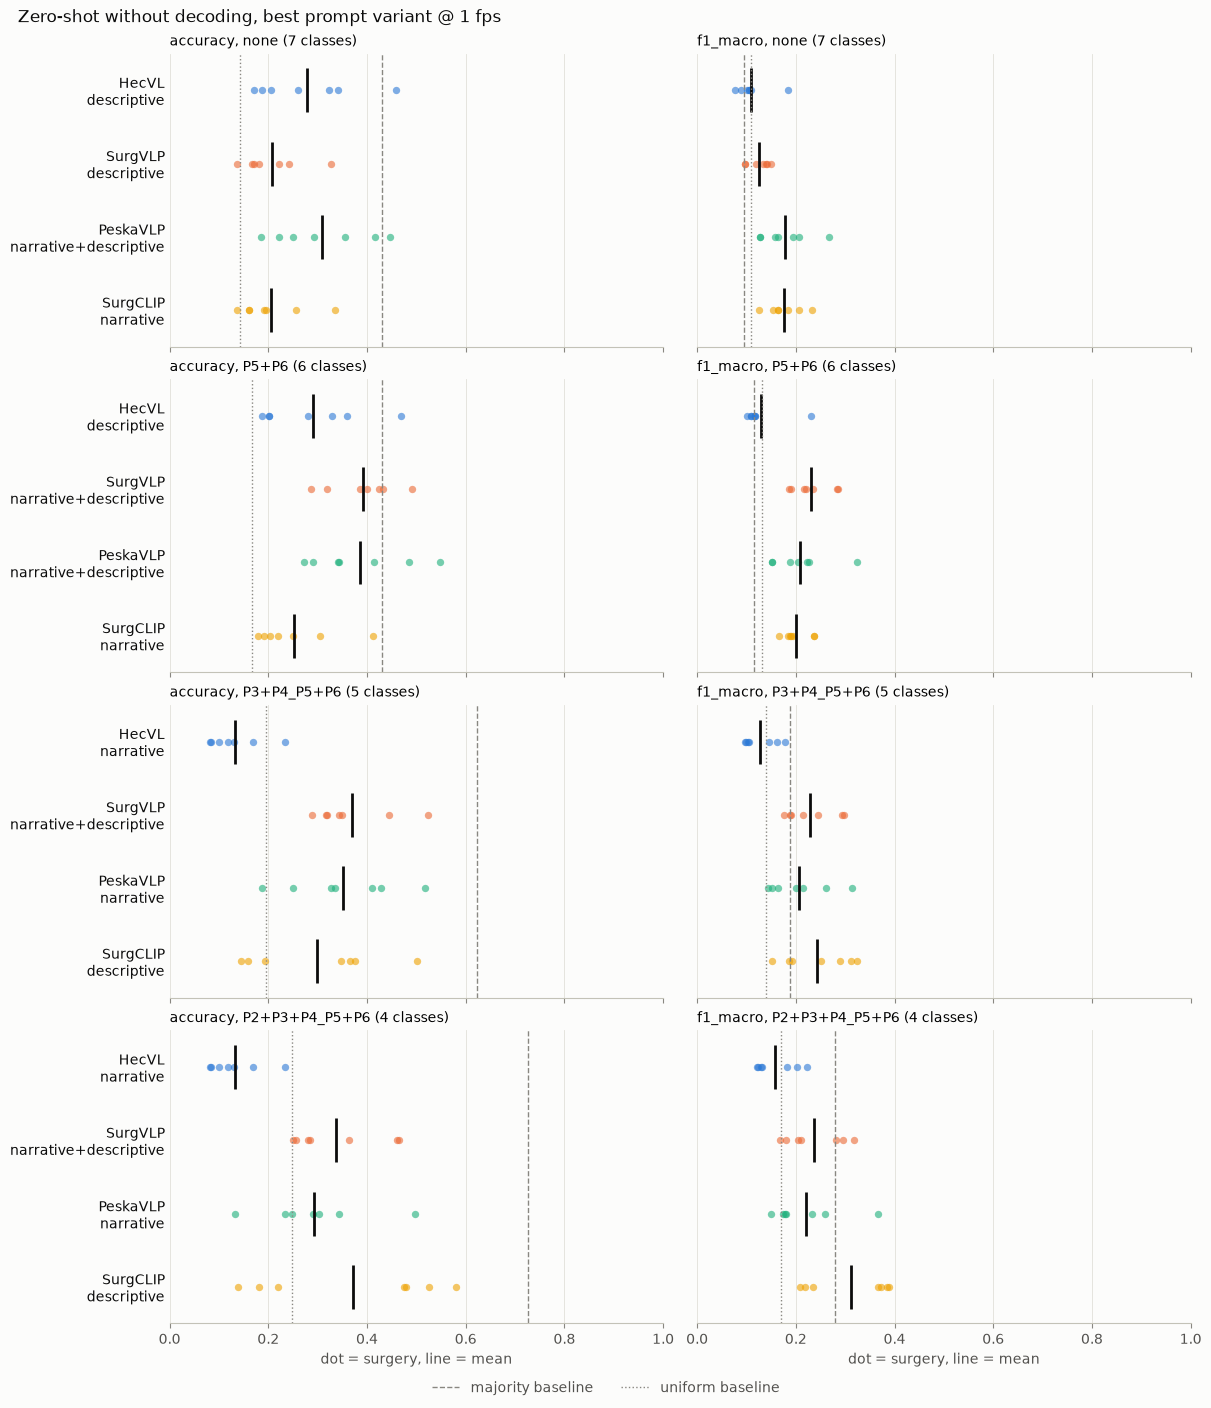

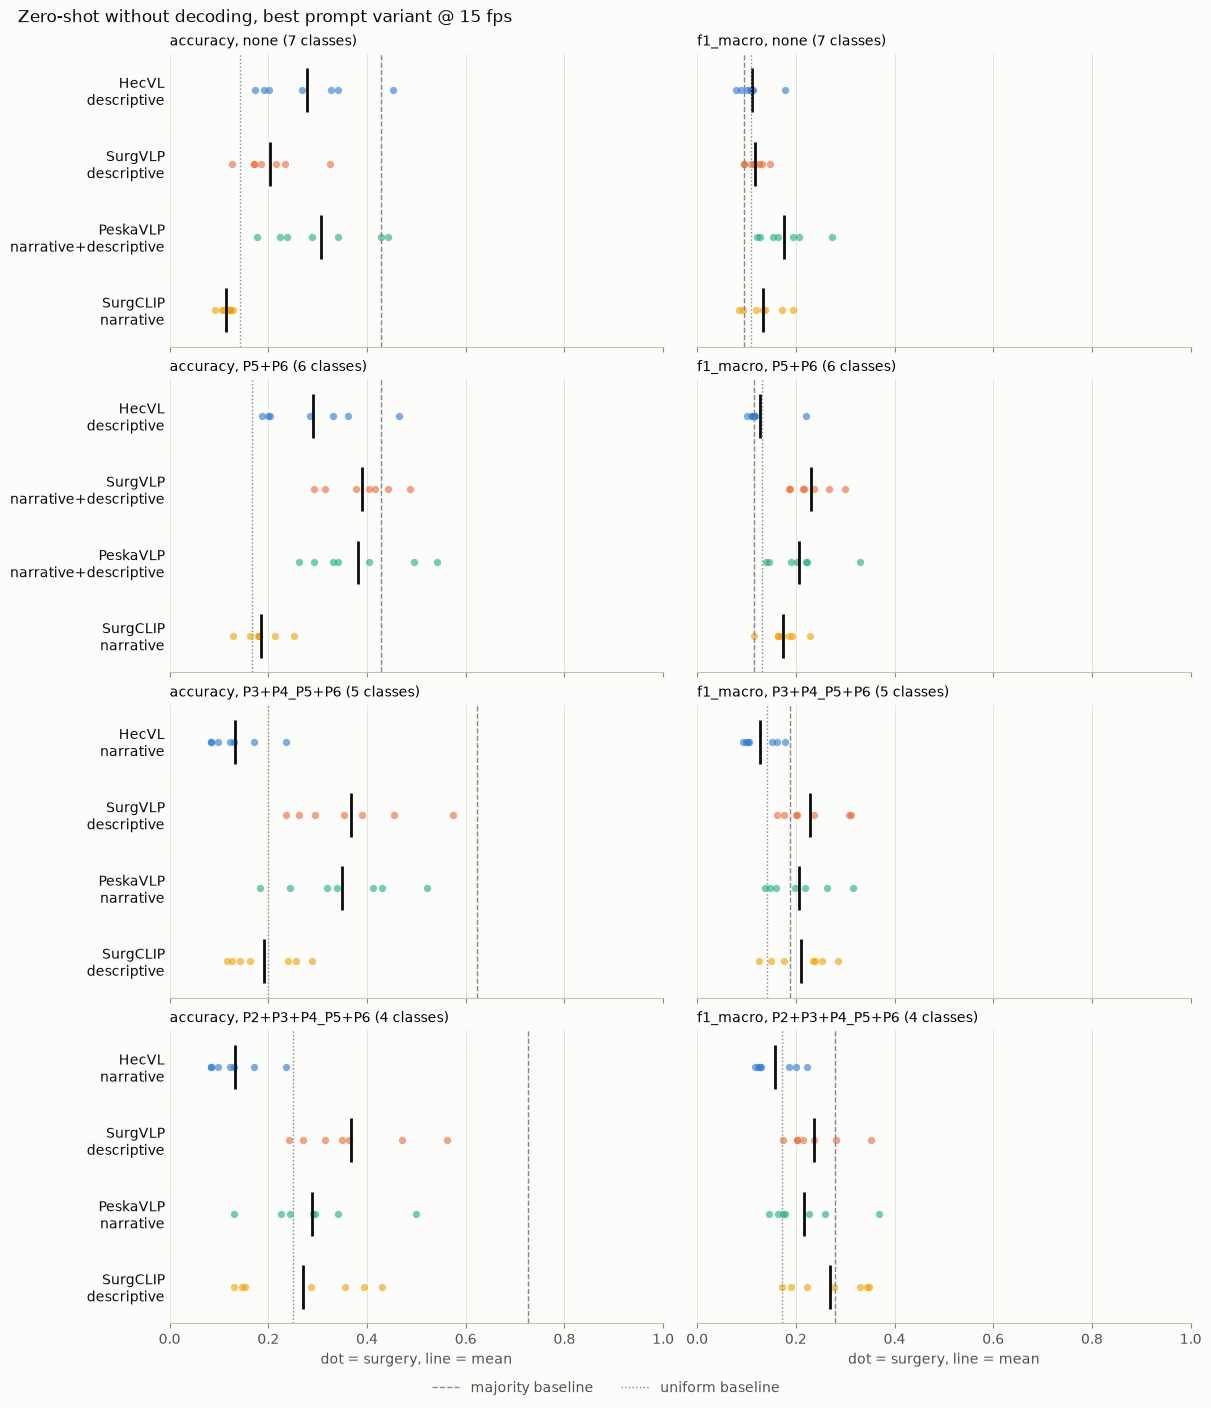

variant and f1_macro: variant with the highest mean over all surgeries (optimistic); f1_macro held-out: variant chosen per test surgery on the other surgeries


variant  accuracy  \
scheme         model             fps                                     
none           HecVL             1.0             descriptive     0.279   
                                 15.0            descriptive     0.279   
               SurgVLP           1.0             descriptive     0.207   
                                 15.0            descriptive     0.204   
               PeskaVLP          1.0   narrative+descriptive     0.309   
                                 15.0  narrative+descriptive     0.306   
               SurgCLIP          1.0               narrative     0.205   
                                 15.0              narrative     0.115   
               majority baseline 1.0                     NaN     0.429   
                                 15.0                    NaN     0.429   
               uniform baseline  1.0                     NaN     0.142   
                                 15.0                    NaN     0.143   
P5+P6          HecVL             1.0             descriptive     0.290   
                                 15.0            descriptive     0.290   
               SurgVLP           1.0   narrative+descriptive     0.391   
                                 15.0  narrative+descriptive     0.391   
               PeskaVLP          1.0   narrative+descriptive     0.385   
                                 15.0  narrative+descriptive     0.381   
               SurgCLIP          1.0               narrative     0.251   
                                 15.0              narrative     0.185   
               majority baseline 1.0                     NaN     0.429   
                                 15.0                    NaN     0.429   
               uniform baseline  1.0                     NaN     0.168   
                                 15.0                    NaN     0.168   
P3+P4_P5+P6    HecVL             1.0               narrative     0.131   
                                 15.0              narrative     0.132   
               SurgVLP           1.0   narrative+descriptive     0.369   
                                 15.0            descriptive     0.367   
               PeskaVLP          1.0               narrative     0.351   
                                 15.0              narrative     0.350   
               SurgCLIP          1.0             descriptive     0.298   
                                 15.0            descriptive     0.191   
               majority baseline 1.0                     NaN     0.623   
                                 15.0                    NaN     0.623   
               uniform baseline  1.0                     NaN     0.195   
                                 15.0                    NaN     0.200   
P2+P3+P4_P5+P6 HecVL             1.0               narrative     0.131   
                                 15.0              narrative     0.132   
               SurgVLP           1.0   narrative+descriptive     0.338   
                                 15.0            descriptive     0.368   
               PeskaVLP          1.0               narrative     0.292   
                                 15.0              narrative     0.289   
               SurgCLIP          1.0             descriptive     0.371   
                                 15.0            descriptive     0.271   
               majority baseline 1.0                     NaN     0.725   
                                 15.0                    NaN     0.725   
               uniform baseline  1.0                     NaN     0.248   
                                 15.0                    NaN     0.250   

                                       f1_macro  edit_score  f1_at_25  \
scheme         model             fps                                    
none           HecVL             1.0      0.110       0.011     0.001   
                                 15.0     0.111       0.002     0.000   
               SurgVLP           1.0      0.125       0.009 

In [21]:
baseline_rows = []
for name, scheme in schemes.items():
    rng = np.random.default_rng(CHANCE_SEED)
    for fps in scheme.fps_values:
        for surgery_id, y in scheme.labels[fps].items():
            others = np.concatenate([other[other != UNLABELLED] for s, other in scheme.labels[fps].items() if s != surgery_id])
            majority = np.full_like(y, np.bincount(others, minlength=scheme.num_phases).argmax())
            uniform = rng.integers(0, scheme.num_phases, size=len(y))
            for baseline, predicted in (("majority", majority), ("uniform", uniform)):
                result = score(y, predicted)
                baseline_rows.append(
                    {
                        "scheme": name,
                        "baseline": baseline,
                        "fps": fps,
                        "surgery_id": surgery_id,
                        **{m: getattr(result, m) for m in {*SUMMARY_METRICS, *COMPARE_METRICS}},
                    }
                )
baselines = pd.DataFrame(baseline_rows)
baseline_summary = baselines.groupby(["scheme", "baseline", "fps"])[[*SUMMARY_METRICS]].mean()

for fps in fps_values:
    fig, axes = plt.subplots(
        len(schemes), 2, figsize=(12, (0.55 * len(models) + 1.1) * len(schemes) + 0.8), layout="constrained", sharex=True, squeeze=False
    )
    for row, (name, scheme) in enumerate(schemes.items()):
        plot_rows = scheme.best_raw[scheme.best_raw["fps"] == fps]
        plot_models = [m for m in models if m in set(plot_rows["model"])]
        for ax, metric in zip(axes[row], ("accuracy", "f1_macro"), strict=True):
            clean_axes(ax, grid_axis="x")
            for position, model in enumerate(plot_models):
                values = plot_rows.loc[plot_rows["model"] == model, metric].to_numpy()
                ax.scatter(values, np.full(len(values), position), s=28, color=MODEL_COLORS[model], alpha=0.6, linewidth=0)
                ax.vlines(values.mean(), position - 0.3, position + 0.3, color=INK, linewidth=2)
            for baseline, style in (("majority", "--"), ("uniform", ":")):
                ax.axvline(
                    baseline_summary.loc[(name, baseline, fps), metric], color=MUTED_INK, linestyle=style, linewidth=1,
                    label=f"{baseline} baseline",
                )
            ax.set_xlim(0, 1)
            ax.set_yticks(range(len(plot_models)), labels=[f"{m}\n{scheme.best_variant[(m, fps)]}" for m in plot_models] if metric == "accuracy" else [])
            ax.set_ylim(len(plot_models) - 0.5, -0.5)
            ax.spines["left"].set_visible(False)
            ax.tick_params(axis="y", length=0, labelcolor=INK)
            ax.set_title(f"{metric}, {name} ({scheme.num_phases} classes)", loc="left", fontsize=10)
    for ax in axes[-1]:
        ax.set_xlabel("dot = surgery, line = mean")
    figure_legend(fig, axes)
    fig.suptitle(f"Zero-shot without decoding, best prompt variant @ {fps:g} fps", x=0.01, ha="left", color=INK)
    plt.show()

overall_tables = {}
for name, scheme in schemes.items():
    overall = scheme.best_raw.groupby(["model", "fps"]).agg(variant=("variant", "first"), **{m: (m, "mean") for m in SUMMARY_METRICS})
    overall["f1_macro held-out"] = held_out_selection(scheme.raw, ["variant"]).groupby(["model", "fps"])["f1_macro"].mean()
    overall = pd.concat(
        [
            overall.reindex(models, level="model"),
            baseline_summary.loc[name].rename(index=lambda b: f"{b} baseline", level="baseline").rename_axis(["model", "fps"]),
        ]
    )
    overall_tables[name] = overall
print(
    "variant and f1_macro: variant with the highest mean over all surgeries (optimistic); "
    "f1_macro held-out: variant chosen per test surgery on the other surgeries"
)
with_scheme(overall_tables).round(3)

## Prompt style comparison

Descriptive against narrative prompts, and both combined, per model.

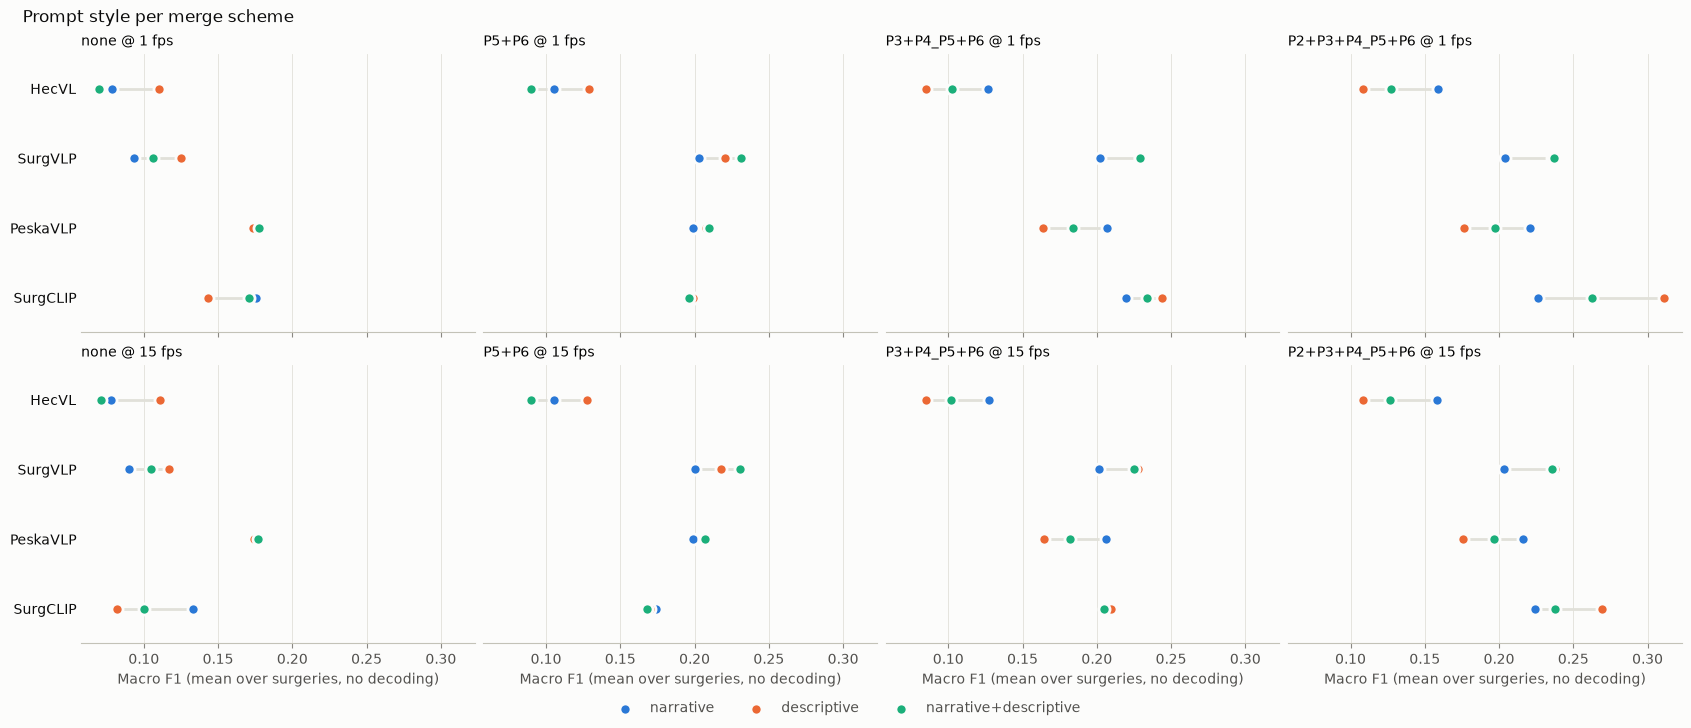

accuracy                                    \
variant                      narrative descriptive narrative+descriptive   
scheme         model    fps                                                
none           HecVL    1.0      0.115       0.279                 0.073   
                        15.0     0.114       0.279                 0.074   
               SurgVLP  1.0      0.159       0.207                 0.189   
                        15.0     0.156       0.204                 0.188   
               PeskaVLP 1.0      0.265       0.328                 0.309   
                        15.0     0.266       0.325                 0.306   
               SurgCLIP 1.0      0.205       0.163                 0.187   
                        15.0     0.115       0.074                 0.081   
P5+P6          HecVL    1.0      0.130       0.290                 0.100   
                        15.0     0.131       0.290                 0.100   
               SurgVLP  1.0      0.337       0.367                 0.391   
                        15.0     0.334       0.367                 0.391   
               PeskaVLP 1.0      0.334       0.406                 0.385   
                        15.0     0.333       0.403                 0.381   
               SurgCLIP 1.0      0.251       0.258                 0.246   
                        15.0     0.185       0.177                 0.170   
P3+P4_P5+P6    HecVL    1.0      0.131       0.078                 0.093   
                        15.0     0.132       0.077                 0.093   
               SurgVLP  1.0      0.316       0.367                 0.369   
                        15.0     0.317       0.367                 0.367   
               PeskaVLP 1.0      0.351       0.275                 0.320   
                        15.0     0.350       0.275                 0.318   
               SurgCLIP 1.0      0.210       0.298                 0.257   
                        15.0     0.176       0.191                 0.172   
P2+P3+P4_P5+P6 HecVL    1.0      0.131       0.080                 0.093   
                        15.0     0.132       0.080                 0.093   
               SurgVLP  1.0      0.262       0.365                 0.338   
                        15.0     0.263       0.368                 0.338   
               PeskaVLP 1.0      0.292       0.258                 0.275   
                        15.0     0.289       0.257                 0.276   
               SurgCLIP 1.0      0.181       0.371                 0.249   
                        15.0     0.179       0.271                 0.204   

                              f1_macro                                    \
variant                      narrative descriptive narrative+descriptive   
scheme         model    fps                                                
none           HecVL    1.0      0.078       0.110                 0.070   
                        15.0     0.078       0.111                 0.071   
               SurgVLP  1.0      0.094       0.125                 0.107   
                        15.0     0.090       0.117                 0.105   
               PeskaVLP 1.0      0.175       0.173                 0.177   
                        15.0     0.175       0.174                 0.177   
               SurgCLIP 1.0      0.176       0.143                 0.171   
                        15.0     0.133       0.082                 0.100   
P5+P6          HecVL    1.0      0.105       0.129                 0.090   
                        15.0     0.105       0.127                 0.090   
               SurgVLP  1.0      0.203       0.221                 0.231   
                        15.0     0.200       0.218                 0.230   
               PeskaVLP 1.0      0.199       0.208                 0.209   
                        15.0     0.199       0.207                 0.207   
               SurgCLIP 1.0      0.199       0.199                 0.197   
 

In [22]:
style_tables = {}
for name, scheme in schemes.items():
    table = scheme.raw.pivot_table(index=["model", "fps"], columns="variant", values=["accuracy", "f1_macro"], aggfunc="mean")
    table = table.reindex(columns=scheme.variants, level="variant").reindex(models, level="model")
    table[("best", "")] = scheme.best_variant
    if len(scheme.variants) > 1:
        table[("combined gain", "")] = table[("f1_macro", scheme.variants[-1])] - table["f1_macro"][scheme.variants[:-1]].max(axis=1)
    style_tables[name] = table

all_variants = list(dict.fromkeys(v for scheme in schemes.values() for v in scheme.variants))
style_colors = {variant: CATEGORICAL[index] for index, variant in enumerate(all_variants)}
fig, axes = plt.subplots(
    len(fps_values), len(schemes), figsize=(4.2 * len(schemes), (0.5 * len(models) + 1.2) * len(fps_values) + 0.8),
    layout="constrained", sharex=True, squeeze=False,
)
for row, fps in enumerate(fps_values):
    for ax, (name, scheme) in zip(axes[row], schemes.items(), strict=True):
        plot_table = style_tables[name].xs(fps, level="fps")["f1_macro"]
        clean_axes(ax, grid_axis="x")
        positions = np.arange(len(plot_table))
        ax.hlines(positions, plot_table.min(axis=1), plot_table.max(axis=1), color=GRIDLINE, linewidth=2)
        for variant in scheme.variants:
            ax.scatter(
                plot_table[variant], positions, s=64, color=style_colors[variant], edgecolor=SURFACE, linewidth=2, zorder=3,
                label=variant,
            )
        ax.set_yticks(positions, labels=plot_table.index if ax is axes[row][0] else [])
        ax.set_ylim(len(models) - 0.5, -0.5)
        ax.spines["left"].set_visible(False)
        ax.tick_params(axis="y", length=0, labelcolor=INK)
        ax.set_title(f"{name} @ {fps:g} fps", loc="left", fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel("Macro F1 (mean over surgeries, no decoding)")
figure_legend(fig, axes)
fig.suptitle("Prompt style per merge scheme", x=0.01, ha="left", color=INK)
plt.show()

with_scheme(style_tables).round(3)

## Per-phase performance

Precision, recall and F1 per phase and model. Which phases the prompts capture and which they miss.

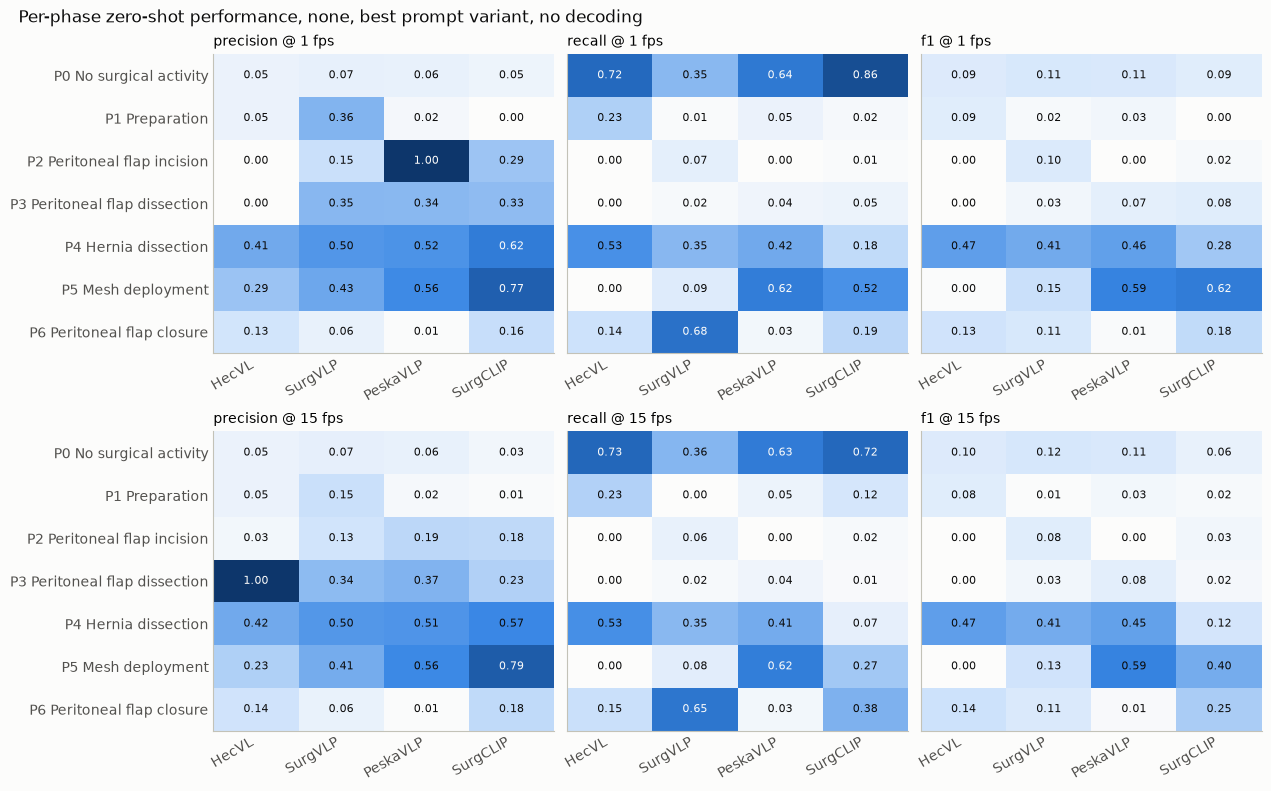

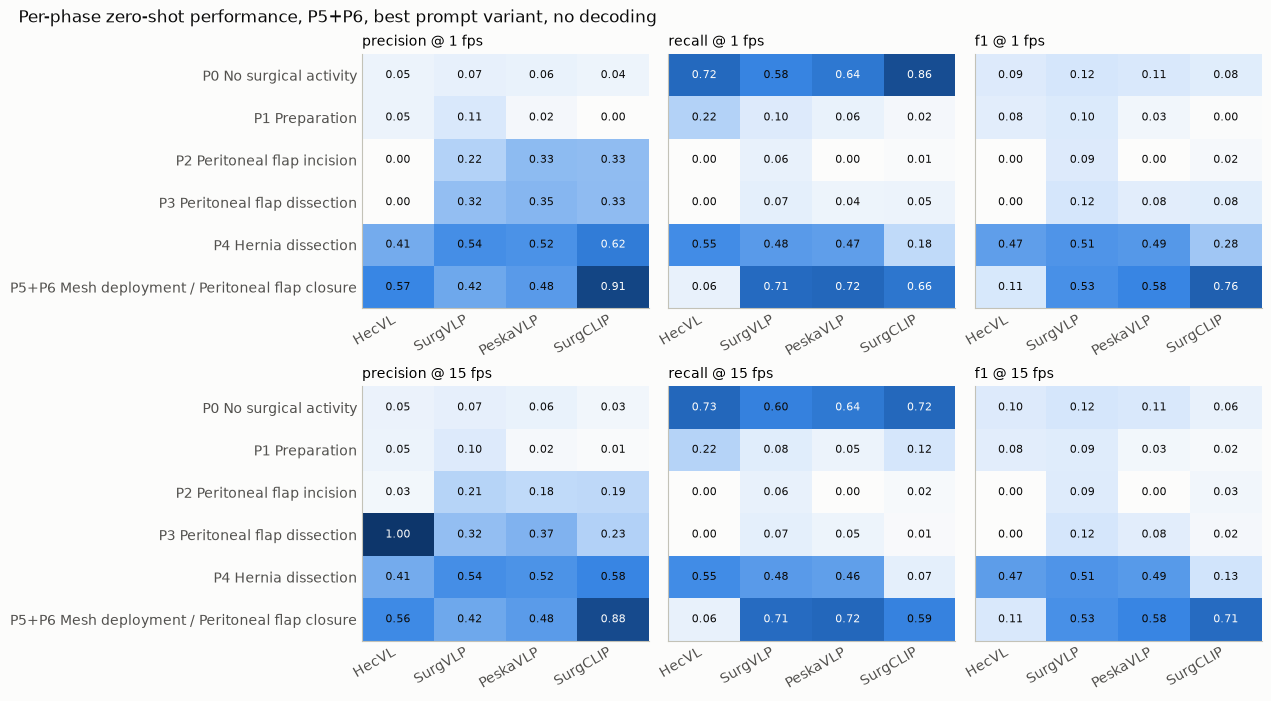

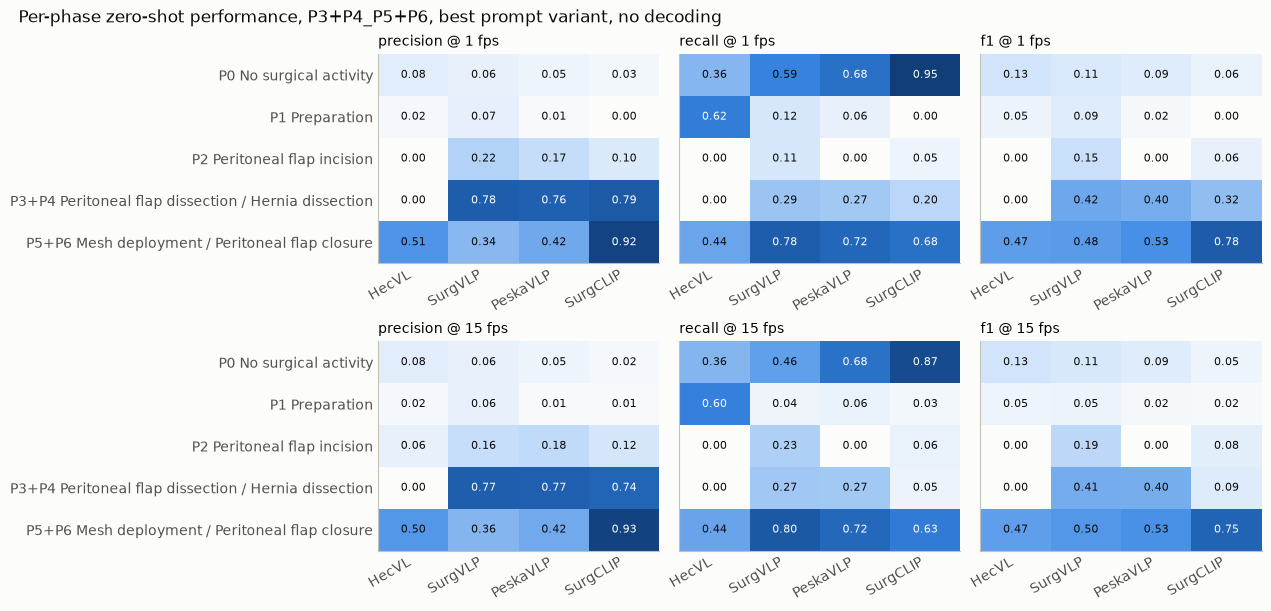

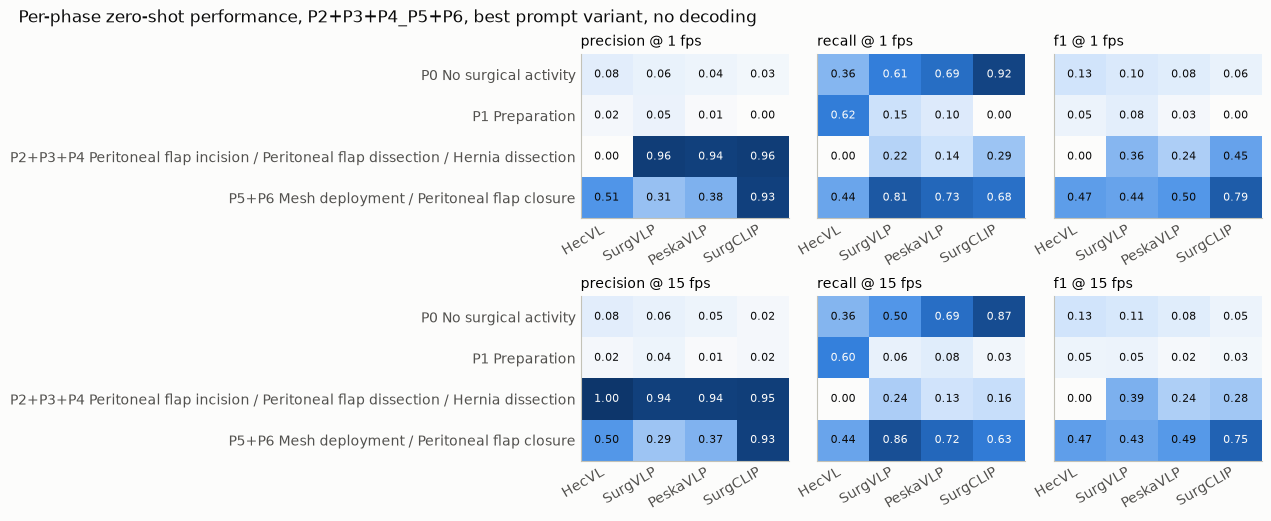

model                    HecVL        SurgVLP        PeskaVLP        SurgCLIP  \
fps                       1.0    15.0    1.0    15.0     1.0    15.0     1.0    
scheme         phase                                                            
none           P0        0.095  0.096   0.111  0.115    0.109  0.108    0.086   
               P1        0.086  0.084   0.018  0.007    0.033  0.029    0.004   
               P2        0.000  0.000   0.099  0.083    0.001  0.000    0.017   
               P3        0.000  0.000   0.034  0.032    0.072  0.077    0.082   
               P4        0.465  0.468   0.411  0.409    0.460  0.454    0.276   
               P5        0.004  0.003   0.149  0.134    0.586  0.587    0.622   
               P6        0.135  0.143   0.110  0.105    0.011  0.012    0.176   
P5+P6          P0        0.094  0.096   0.118  0.120    0.106  0.106    0.084   
               P1        0.080  0.079   0.100  0.089    0.034  0.029    0.004   
               P2        0.000  0.000   0.094  0.092    0.001  0.000    0.021   
               P3        0.000  0.000   0.120  0.120    0.079  0.081    0.083   
               P4        0.467  0.470   0.509  0.508    0.493  0.488    0.280   
               P5+P6     0.111  0.106   0.531  0.530    0.578  0.575    0.764   
P3+P4_P5+P6    P0        0.130  0.131   0.108  0.113    0.086  0.086    0.058   
               P1        0.047  0.046   0.087  0.051    0.021  0.020    0.000   
               P2        0.000  0.001   0.151  0.192    0.001  0.001    0.063   
               P3+P4     0.000  0.000   0.423  0.405    0.399  0.400    0.320   
               P5+P6     0.469  0.466   0.478  0.499    0.530  0.527    0.782   
P2+P3+P4_P5+P6 P0        0.130  0.131   0.105  0.110    0.084  0.085    0.056   
               P1        0.047  0.046   0.078  0.050    0.025  0.022    0.000   
               P2+P3+P4  0.000  0.000   0.355  0.387    0.239  0.236    0.447   
               P5+P6     0.469  0.466   0.443  0.429    0.498  0.492    0.789   

model                           
fps                       15.0  
scheme         phase            
none           P0        0.062  
               P1        0.018  
               P2        0.032  
               P3        0.024  
               P4        0.123  
               P5        0.402  
               P6        0.247  
P5+P6          P0        0.061  
               P1        0.019  
               P2        0.033  
               P3        0.024  
               P4        0.131  
               P5+P6     0.706  
P3+P4_P5+P6    P0        0.047  
               P1        0.019  
               P2        0.077  
               P3+P4     0.091  
               P5+P6     0.748  
P2+P3+P4_P5+P6 P0        0.047  
               P1        0.028  
               P2+P3+P4  0.276  
               P5+P6     0.750

In [23]:
phase_rows = []
for name, scheme in schemes.items():
    for key in scheme.best_keys:
        y, p = pooled(scheme, key)
        precision, recall, f1, support = precision_recall_fscore_support(
            y, p.argmax(axis=1), labels=range(scheme.num_phases), zero_division=0
        )
        for index, phase in enumerate(scheme.phase_ids):
            phase_rows.append(
                {
                    "scheme": name, "model": key[0], "fps": key[1], "phase": phase, "order": index,
                    "precision": precision[index], "recall": recall[index], "f1": f1[index], "support": support[index],
                }
            )
per_phase = pd.DataFrame(phase_rows)

phase_metrics = ["precision", "recall", "f1"]
for name, scheme in schemes.items():
    fig, axes = plt.subplots(
        len(scheme.fps_values), len(phase_metrics),
        figsize=(4.2 * len(phase_metrics), 0.45 * scheme.num_phases * len(scheme.fps_values) + 1.5),
        layout="constrained", squeeze=False,
    )
    for row, fps in enumerate(scheme.fps_values):
        plot_table = per_phase[(per_phase["scheme"] == name) & (per_phase["fps"] == fps)]
        for ax, metric in zip(axes[row], phase_metrics, strict=True):
            matrix = plot_table.pivot(index="phase", columns="model", values=metric).reindex(index=scheme.phase_ids)
            matrix = matrix[[m for m in models if m in matrix.columns]]
            style_axes(ax)
            ax.imshow(matrix.to_numpy(), cmap=SEQUENTIAL, vmin=0, vmax=1, aspect="auto")
            annotate_heatmap(ax, matrix.to_numpy())
            ax.set_xticks(range(len(matrix.columns)), labels=matrix.columns, rotation=30, ha="right")
            ax.set_yticks(range(scheme.num_phases), labels=scheme.phase_names if ax is axes[row][0] else [""] * scheme.num_phases)
            ax.tick_params(length=0)
            ax.set_title(f"{metric} @ {fps:g} fps", loc="left", fontsize=10)
    fig.suptitle(f"Per-phase zero-shot performance, {name}, best prompt variant, no decoding", x=0.01, ha="left", color=INK)
    plt.show()

(
    per_phase.pivot_table(index=["scheme", "order", "phase"], columns=["model", "fps"], values="f1")
    .reindex(scheme_names, level="scheme")
    .reindex(columns=models, level="model")
    .droplevel("order")
    .round(3)
)

## Confusion matrices

Row-normalised confusion matrices per model for the best prompt style.

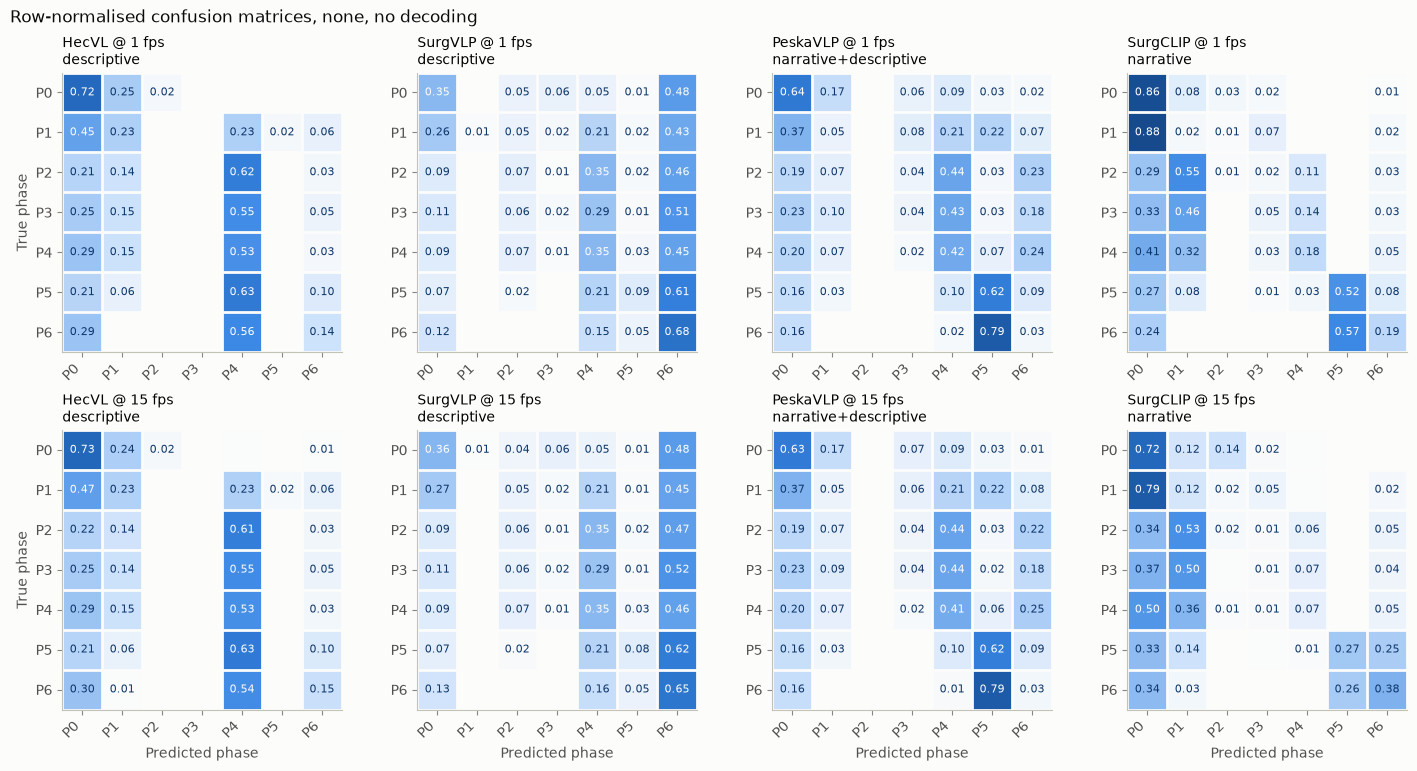

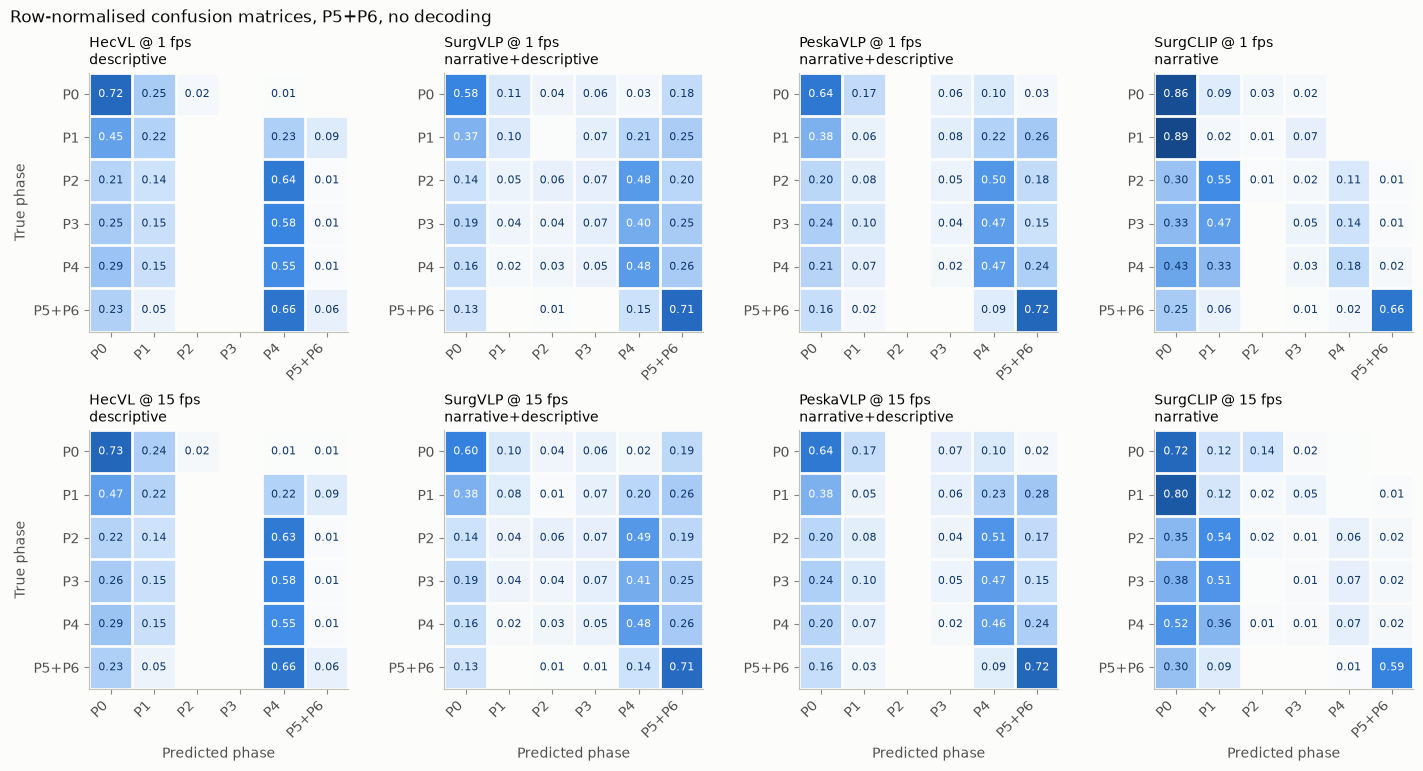

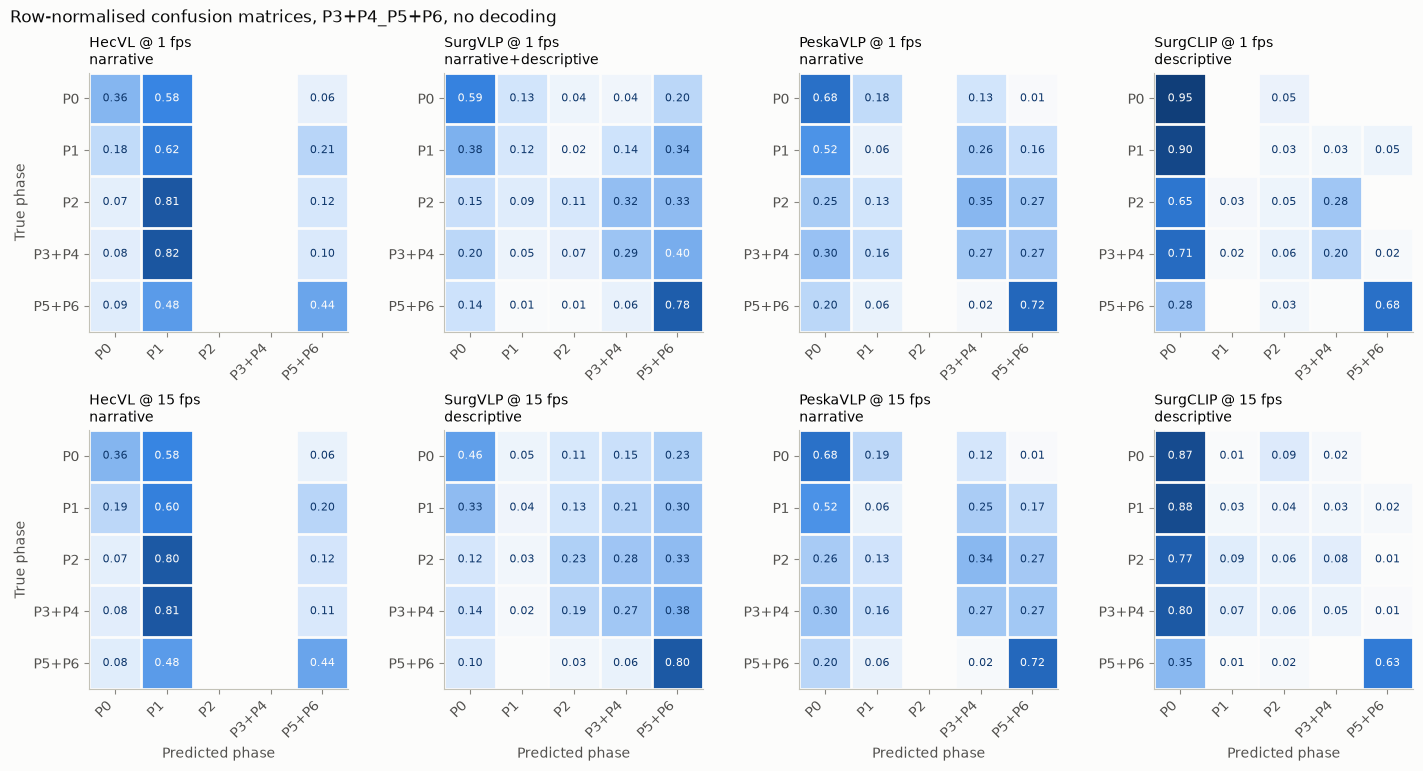

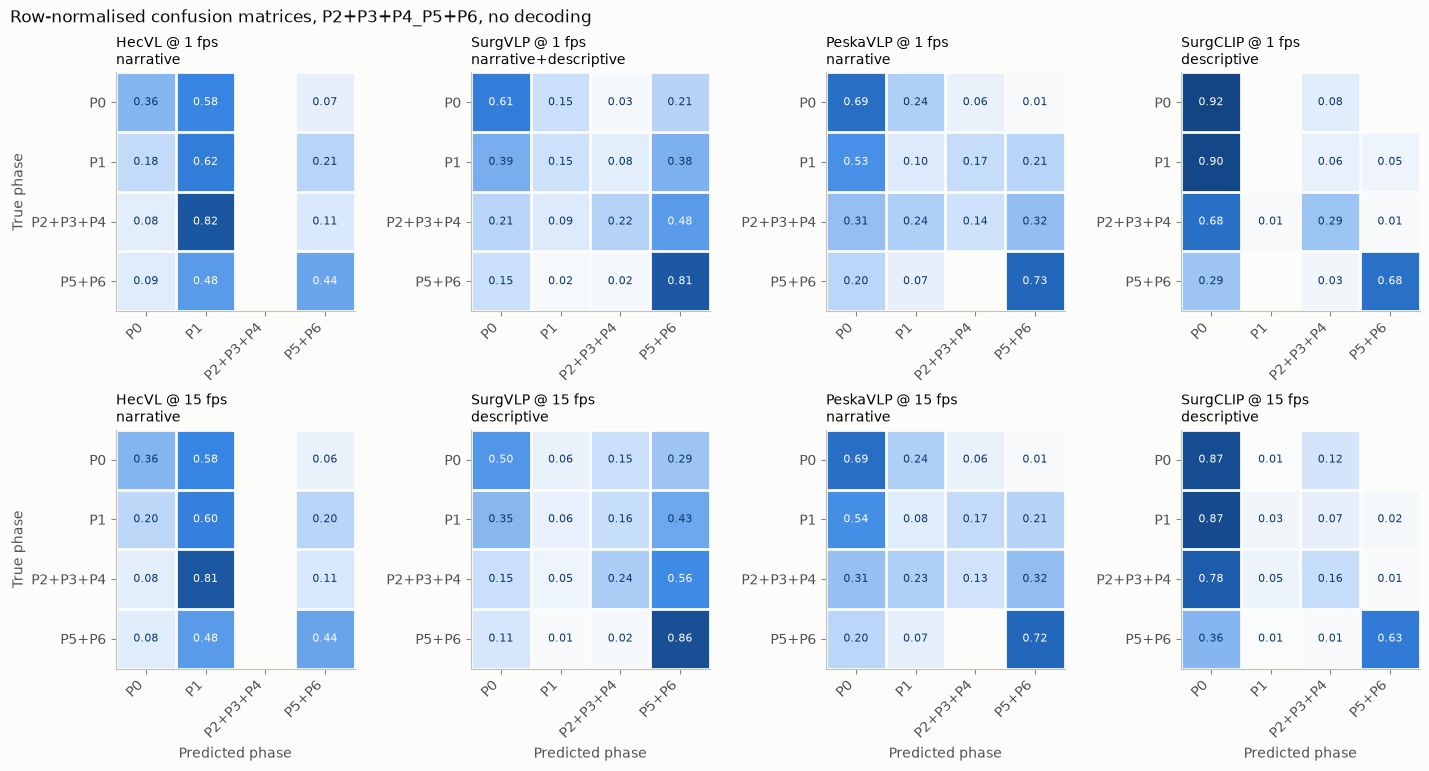

In [24]:
for name, scheme in schemes.items():
    fig, axes = plt.subplots(
        len(scheme.fps_values), len(models), figsize=(3.6 * len(models), 3.6 * len(scheme.fps_values) + 0.4),
        layout="constrained", squeeze=False,
    )
    for row, fps in enumerate(scheme.fps_values):
        for column, model in enumerate(models):
            ax = axes[row][column]
            key = (model, fps, scheme.best_variant.get((model, fps)))
            if key not in scheme.probabilities:
                ax.set_visible(False)
                continue
            y, p = pooled(scheme, key)
            plot_confusion_matrix(y, p.argmax(axis=1), scheme.phase_ids, ax=ax)
            ax.set_title(f"{model} @ {fps:g} fps\n{key[2]}", loc="left", fontsize=10)
            if column:
                ax.set_ylabel("")
            if row < len(scheme.fps_values) - 1:
                ax.set_xlabel("")
    fig.suptitle(f"Row-normalised confusion matrices, {name}, no decoding", x=0.01, ha="left", color=INK)
    plt.show()

## Prediction bias

Predicted phase distribution against the ground truth. Shows whether predictions collapse onto a few phases.

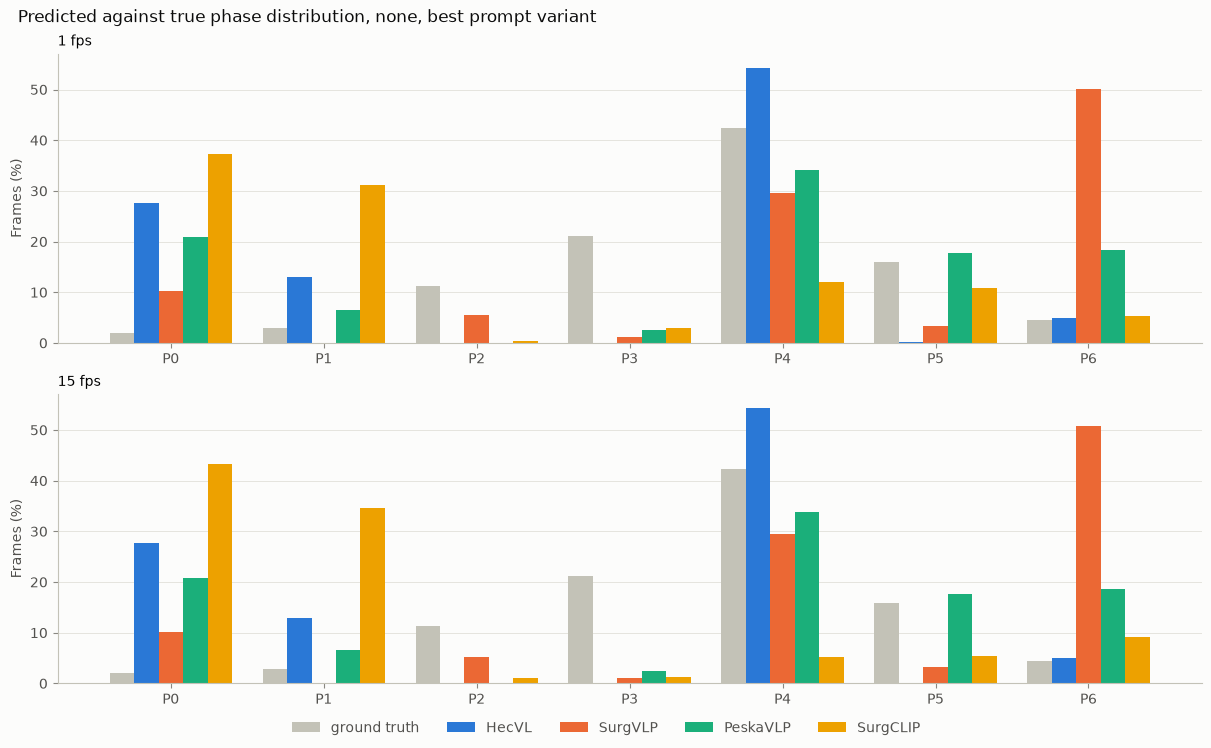

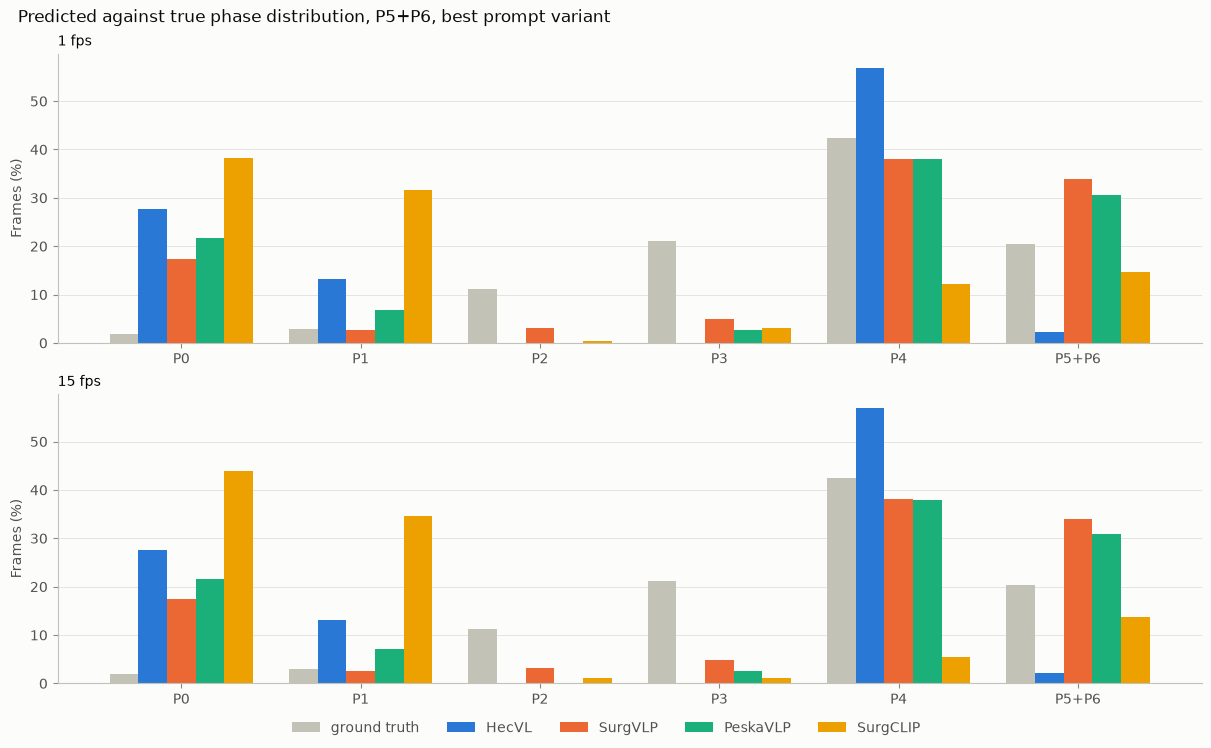

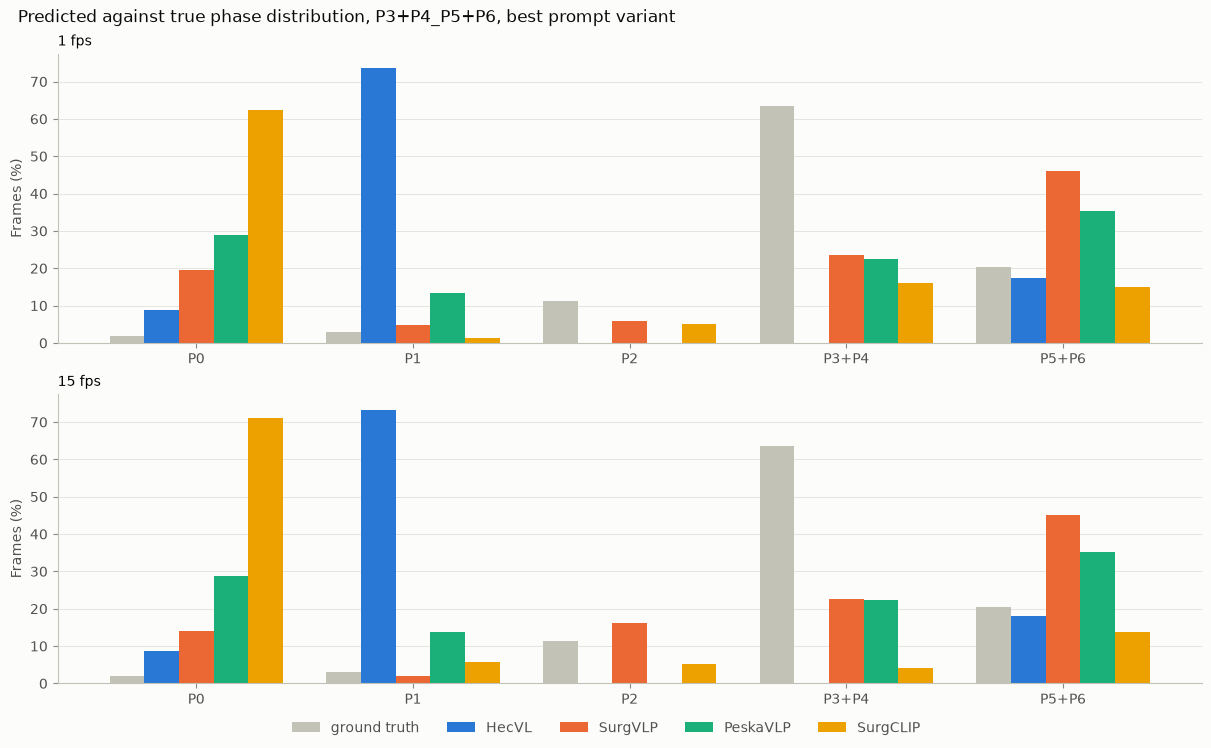

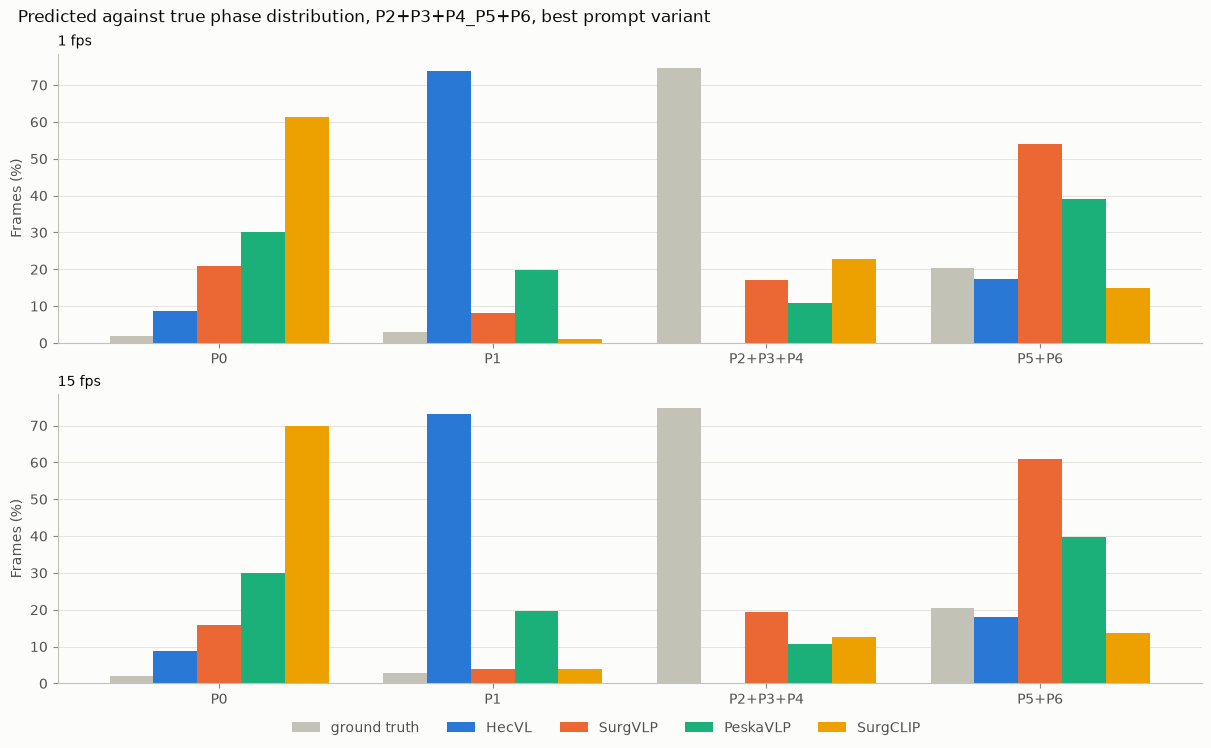

top phase  top share  \
scheme         model    fps  variant                                      
none           HecVL    1.0  narrative                    P1      0.657   
                             descriptive                  P4      0.543   
                             narrative+descriptive        P1      0.693   
                        15.0 narrative                    P1      0.655   
                             descriptive                  P4      0.543   
...                                                      ...        ...   
P2+P3+P4_P5+P6 SurgCLIP 1.0  descriptive                  P0      0.613   
                             narrative+descriptive        P0      0.569   
                        15.0 narrative                    P0      0.448   
                             descriptive                  P0      0.697   
                             narrative+descriptive        P0      0.613   

                                                   never predicted  \
scheme         model    fps  variant                                 
none           HecVL    1.0  narrative                               
                             descriptive                        P3   
                             narrative+descriptive              P3   
                        15.0 narrative                               
                             descriptive                             
...                                                            ...   
P2+P3+P4_P5+P6 SurgCLIP 1.0  descriptive                             
                             narrative+descriptive                   
                        15.0 narrative                               
                             descriptive                             
                             narrative+descriptive                   

                                                    normalised entropy  \
scheme         model    fps  variant                                     
none           HecVL    1.0  narrative                           0.430   
                             descriptive                         0.572   
                             narrative+descriptive               0.473   
                        15.0 narrative                           0.432   
                             descriptive                         0.571   
...                                                                ...   
P2+P3+P4_P5+P6 SurgCLIP 1.0  descriptive                         0.697   
                             narrative+descriptive               0.824   
                        15.0 narrative                           0.811   
                             descriptive                         0.658   
                             narrative+descriptive               0.766   

                                                    total variation  
scheme         model    fps  variant                                 
none           HecVL    1.0  narrative                        0.791  
                             descriptive                      0.481  
                             narrative+descriptive            0.848  
                        15.0 narrative                        0.791  
                             descriptive                      0.481  
...                                                             ...  
P2+P3+P4_P5+P6 SurgCLIP 1.0  descriptive                      0.594  
                             narrative+descriptive            0.710  
                        15.0 narrative                        0.776  
                             descriptive                      0.687  
                             narrative+descriptive            0.755  

[96 rows x 5 columns]

In [25]:
bias_tables = {}
for name, scheme in schemes.items():
    true_share = {}
    for fps in scheme.fps_values:
        counts = np.bincount(np.concatenate([y[y != UNLABELLED] for y in scheme.labels[fps].values()]), minlength=scheme.num_phases)
        true_share[fps] = counts / counts.sum()
    rows, predicted_share = [], {}
    for key in scheme.keys:
        y, p = pooled(scheme, key)
        share = np.bincount(p.argmax(axis=1), minlength=scheme.num_phases) / len(y)
        predicted_share[key] = share
        rows.append(
            {
                "model": key[0],
                "fps": key[1],
                "variant": key[2],
                "top phase": scheme.phase_ids[share.argmax()],
                "top share": share.max(),
                "never predicted": ", ".join(scheme.phase_ids[i] for i in np.flatnonzero(share == 0)),
                "normalised entropy": entropy(share, base=scheme.num_phases),
                "total variation": 0.5 * np.abs(share - true_share[key[1]]).sum(),
            }
        )
    bias_tables[name] = pd.DataFrame(rows).set_index(["model", "fps", "variant"]).reindex(models, level="model")

    fig, axes = plt.subplots(
        len(scheme.fps_values), 1, figsize=(12, 3.4 * len(scheme.fps_values) + 0.6), layout="constrained", sharey=True, squeeze=False
    )
    for ax, fps in zip(axes[:, 0], scheme.fps_values, strict=True):
        clean_axes(ax)
        plot_keys = [key for key in scheme.best_keys if key[1] == fps]
        plot_keys.sort(key=lambda key: models.index(key[0]))
        width = 0.8 / (len(plot_keys) + 1)
        positions = np.arange(scheme.num_phases)
        ax.bar(positions - 0.4 + width / 2, true_share[fps] * 100, width, color=NEUTRAL, label="ground truth")
        for index, key in enumerate(plot_keys, start=1):
            ax.bar(positions - 0.4 + width * (index + 0.5), predicted_share[key] * 100, width, color=MODEL_COLORS[key[0]], label=key[0])
        ax.set_xticks(positions, labels=scheme.phase_ids)
        ax.set_ylabel("Frames (%)")
        ax.set_title(f"{fps:g} fps", loc="left", fontsize=10)
    figure_legend(fig, axes)
    fig.suptitle(f"Predicted against true phase distribution, {name}, best prompt variant", x=0.01, ha="left", color=INK)
    plt.show()

bias = with_scheme(bias_tables)
bias.round(3)

## Confidence and calibration

Distribution of the top-class probability for correct and wrong predictions, and reliability per model.

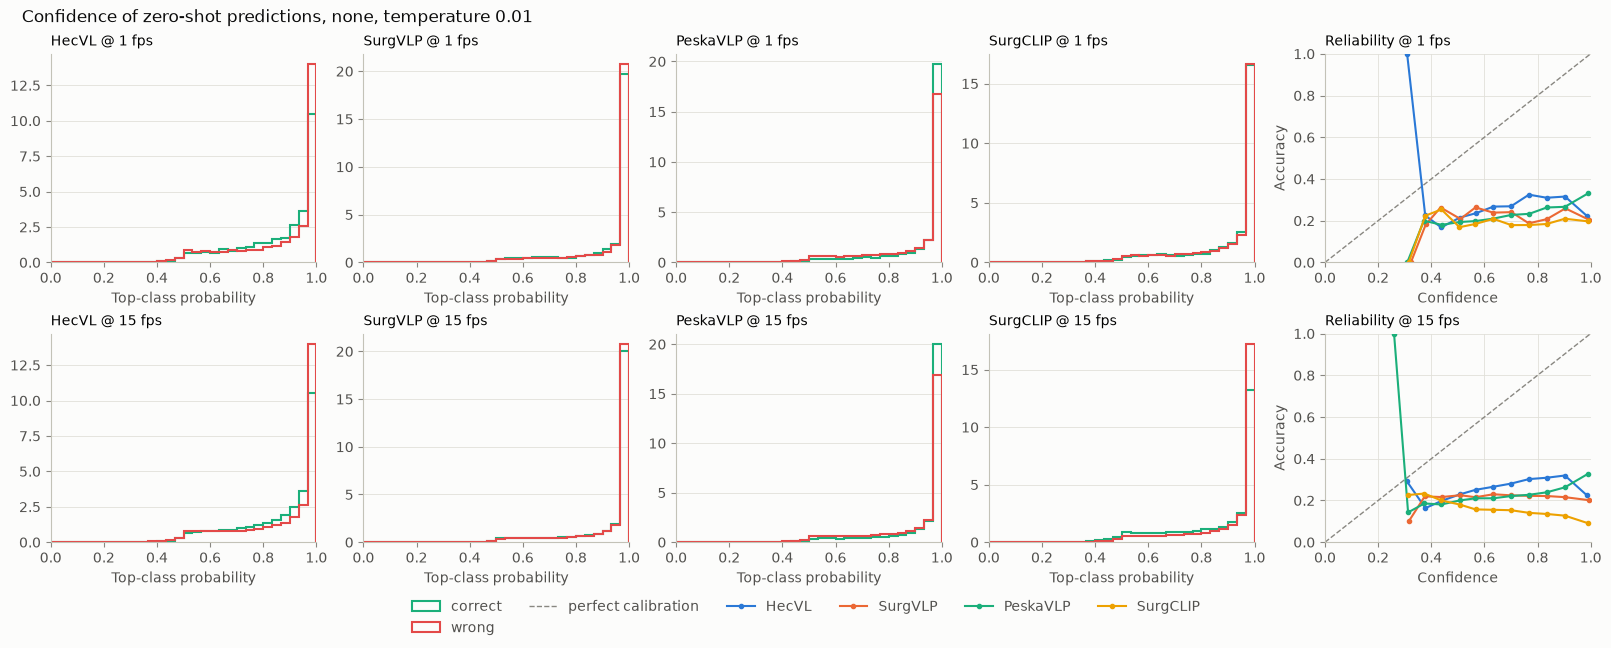

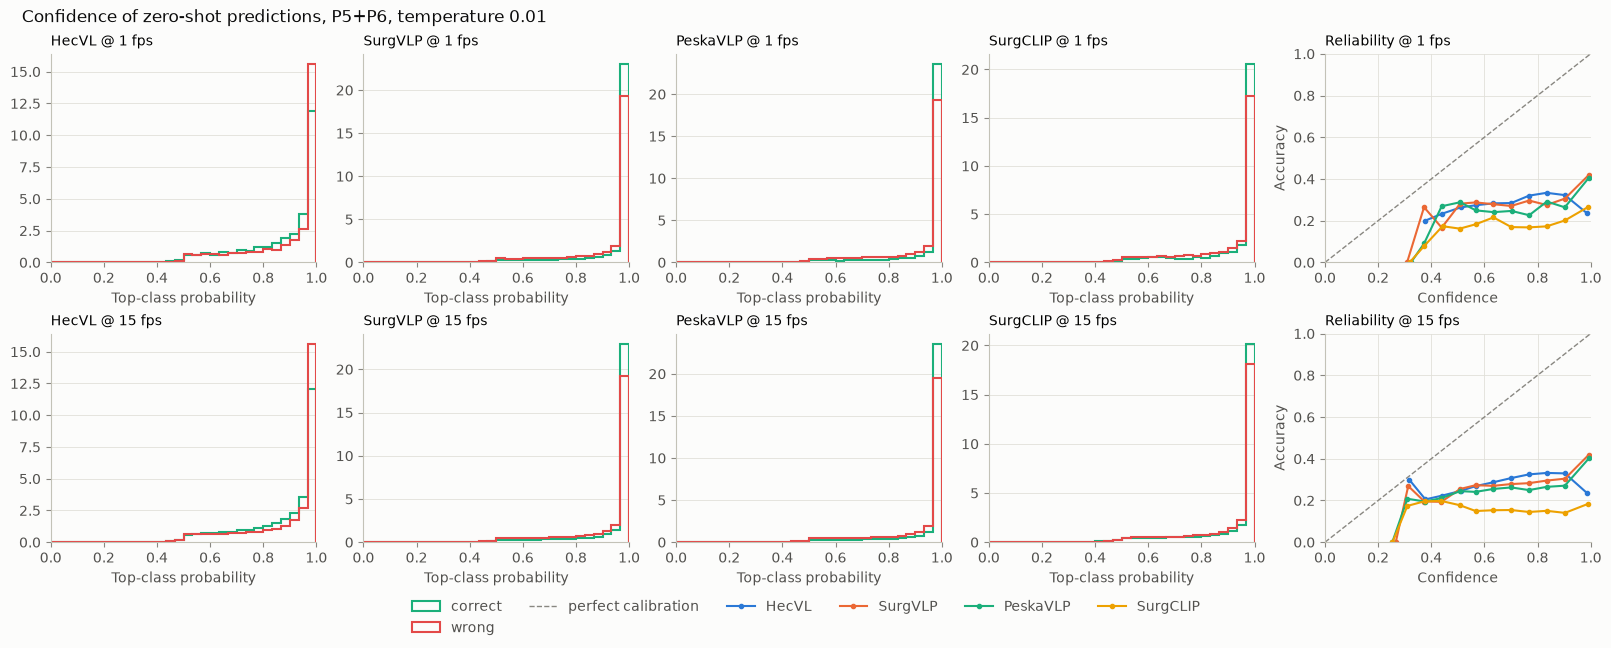

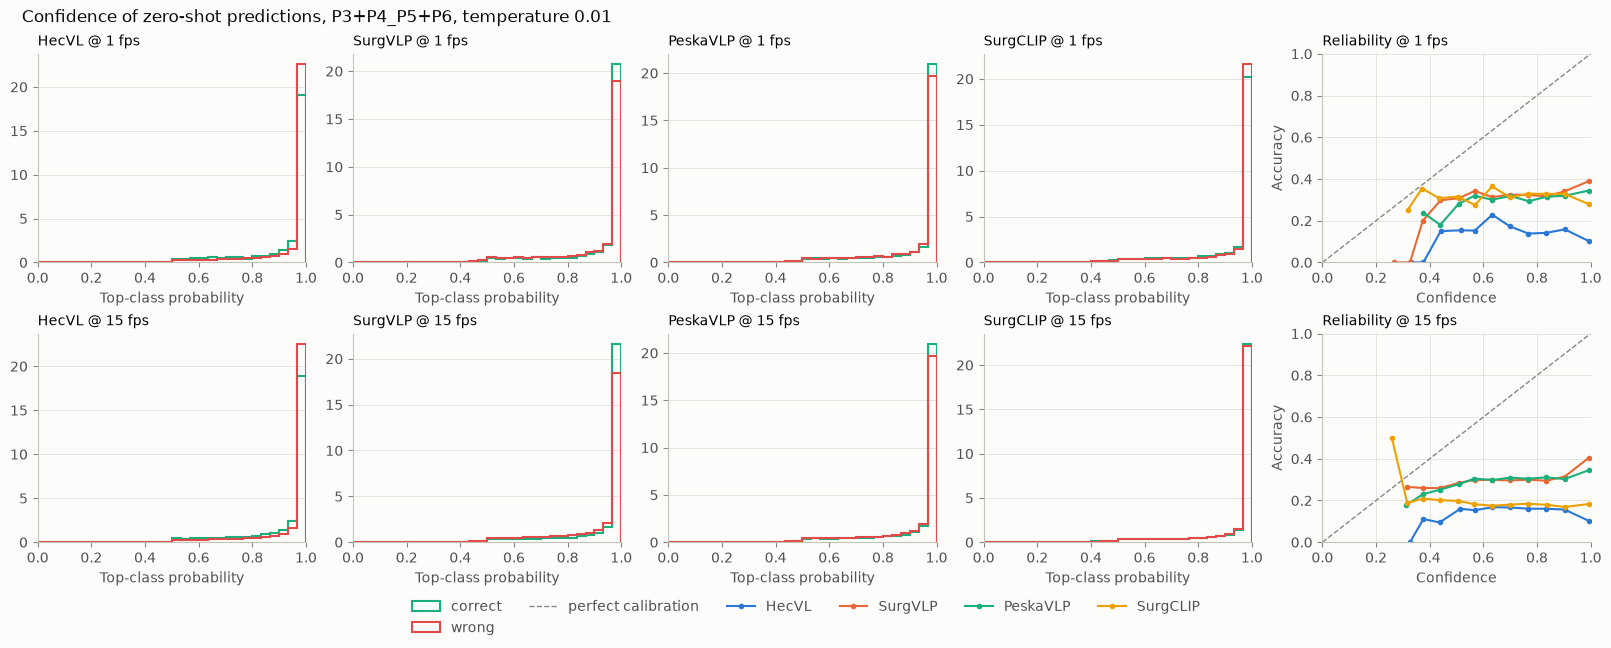

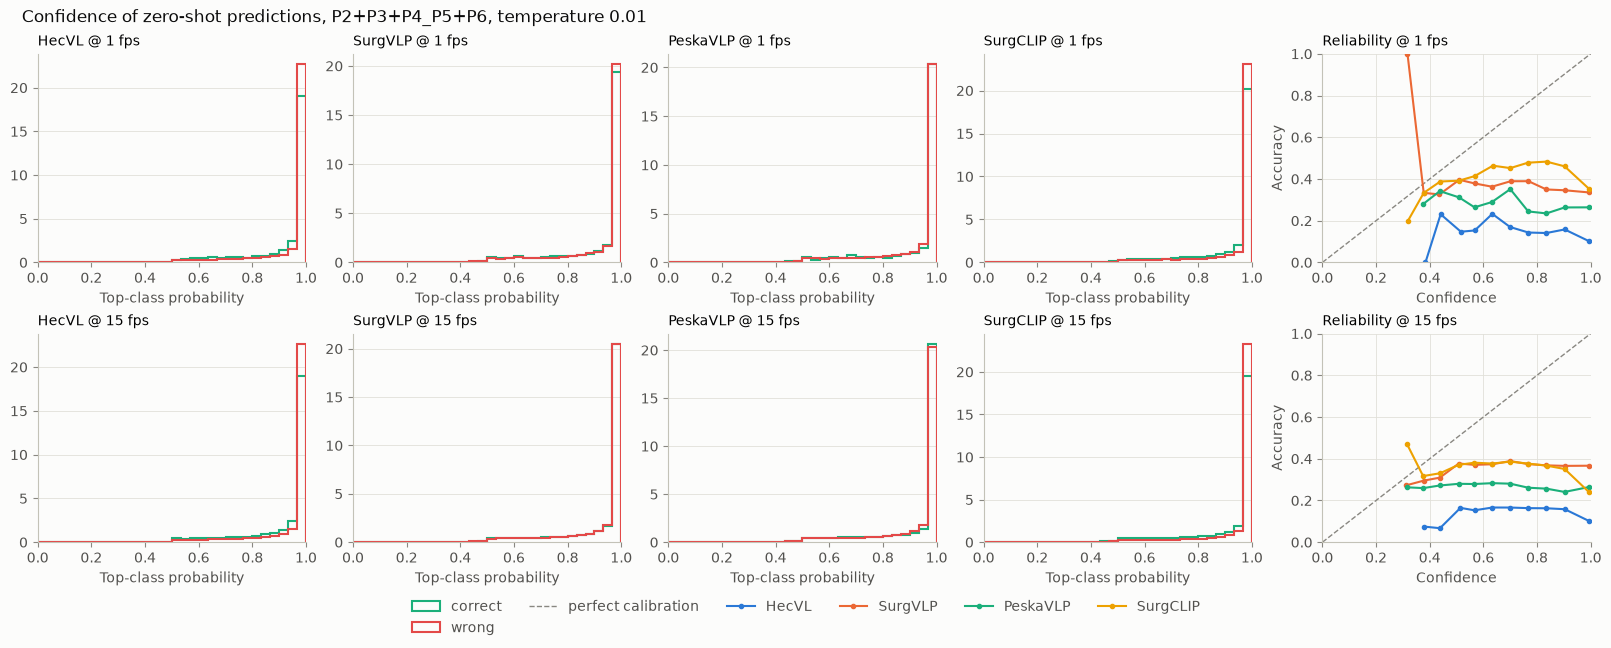

accuracy  mean confidence  \
scheme         model    fps  variant                                            
none           HecVL    1.0  narrative                 0.103            0.936   
                             descriptive               0.252            0.871   
                             narrative+descriptive     0.059            0.926   
                        15.0 narrative                 0.102            0.937   
                             descriptive               0.254            0.872   
...                                                      ...              ...   
P2+P3+P4_P5+P6 SurgCLIP 1.0  descriptive               0.375            0.941   
                             narrative+descriptive     0.248            0.911   
                        15.0 narrative                 0.171            0.922   
                             descriptive               0.266            0.942   
                             narrative+descriptive     0.201            0.923   

                                                    confidence correct  \
scheme         model    fps  variant                                     
none           HecVL    1.0  narrative                           0.935   
                             descriptive                         0.864   
                             narrative+descriptive               0.828   
                        15.0 narrative                           0.936   
                             descriptive                         0.862   
...                                                                ...   
P2+P3+P4_P5+P6 SurgCLIP 1.0  descriptive                         0.930   
                             narrative+descriptive               0.894   
                        15.0 narrative                           0.921   
                             descriptive                         0.919   
                             narrative+descriptive               0.906   

                                                    confidence wrong    ECE  
scheme         model    fps  variant                                         
none           HecVL    1.0  narrative                         0.936  0.833  
                             descriptive                       0.874  0.619  
                             narrative+descriptive             0.932  0.867  
                        15.0 narrative                         0.937  0.834  
                             descriptive                       0.875  0.617  
...                                                              ...    ...  
P2+P3+P4_P5+P6 SurgCLIP 1.0  descriptive                       0.948  0.566  
                             narrative+descriptive             0.916  0.663  
                        15.0 narrative                         0.923  0.751  
                             descriptive                       0.950  0.676  
                             narrative+descriptive             0.927  0.722  

[96 rows x 5 columns]

In [26]:
calibration_tables = {}
bins = np.linspace(0, 1, CONFIDENCE_BINS + 1)
for name, scheme in schemes.items():
    rows, reliability, confidences = [], {}, {}
    for key in scheme.keys:
        y, p = pooled(scheme, key)
        confidence = p.max(axis=1)
        correct = p.argmax(axis=1) == y
        confidences[key] = confidence, correct
        if correct.any() and not correct.all():
            reliability[key] = calibration_curve(correct, confidence, n_bins=CALIBRATION_BINS)
        rows.append(
            {
                "model": key[0],
                "fps": key[1],
                "variant": key[2],
                "accuracy": correct.mean(),
                "mean confidence": confidence.mean(),
                "confidence correct": confidence[correct].mean() if correct.any() else np.nan,
                "confidence wrong": confidence[~correct].mean() if not correct.all() else np.nan,
                "ECE": multiclass_calibration_error(
                    torch.from_numpy(p).float(), torch.from_numpy(y), num_classes=scheme.num_phases, n_bins=CALIBRATION_BINS, norm="l1"
                ).item(),
            }
        )
    calibration_tables[name] = pd.DataFrame(rows).set_index(["model", "fps", "variant"]).reindex(models, level="model")

    fig, axes = plt.subplots(
        len(scheme.fps_values), len(models) + 1, figsize=(3.2 * (len(models) + 1), 2.9 * len(scheme.fps_values) + 0.6),
        layout="constrained", squeeze=False,
    )
    for row, fps in enumerate(scheme.fps_values):
        for column, model in enumerate(models):
            ax = axes[row][column]
            key = (model, fps, scheme.best_variant.get((model, fps)))
            if key not in confidences:
                ax.set_visible(False)
                continue
            clean_axes(ax)
            confidence, correct = confidences[key]
            ax.hist(confidence[correct], bins=bins, density=True, histtype="step", linewidth=1.5, color=CATEGORICAL[2], label="correct")
            ax.hist(confidence[~correct], bins=bins, density=True, histtype="step", linewidth=1.5, color=CATEGORICAL[7], label="wrong")
            ax.set_xlim(0, 1)
            ax.set_title(f"{model} @ {fps:g} fps", loc="left", fontsize=10)
            ax.set_xlabel("Top-class probability")
        ax = axes[row][-1]
        clean_axes(ax, grid_axis="both")
        ax.plot([0, 1], [0, 1], color=MUTED_INK, linestyle="--", linewidth=1, label="perfect calibration")
        for model in models:
            key = (model, fps, scheme.best_variant.get((model, fps)))
            if key in reliability:
                fraction, mean_confidence = reliability[key]
                ax.plot(mean_confidence, fraction, marker="o", markersize=3, color=MODEL_COLORS[model], label=model)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_xlabel("Confidence")
        ax.set_ylabel("Accuracy")
        ax.set_title(f"Reliability @ {fps:g} fps", loc="left", fontsize=10)
    figure_legend(fig, axes)
    fig.suptitle(
        f"Confidence of zero-shot predictions, {name}, temperature {scheme.run.get('temperature', 'unknown')}",
        x=0.01, ha="left", color=INK,
    )
    plt.show()

calibration = with_scheme(calibration_tables)
calibration.round(3)

## Temporal decoding

Effect of smoothing and HMM decoding on zero-shot predictions, per model and method.

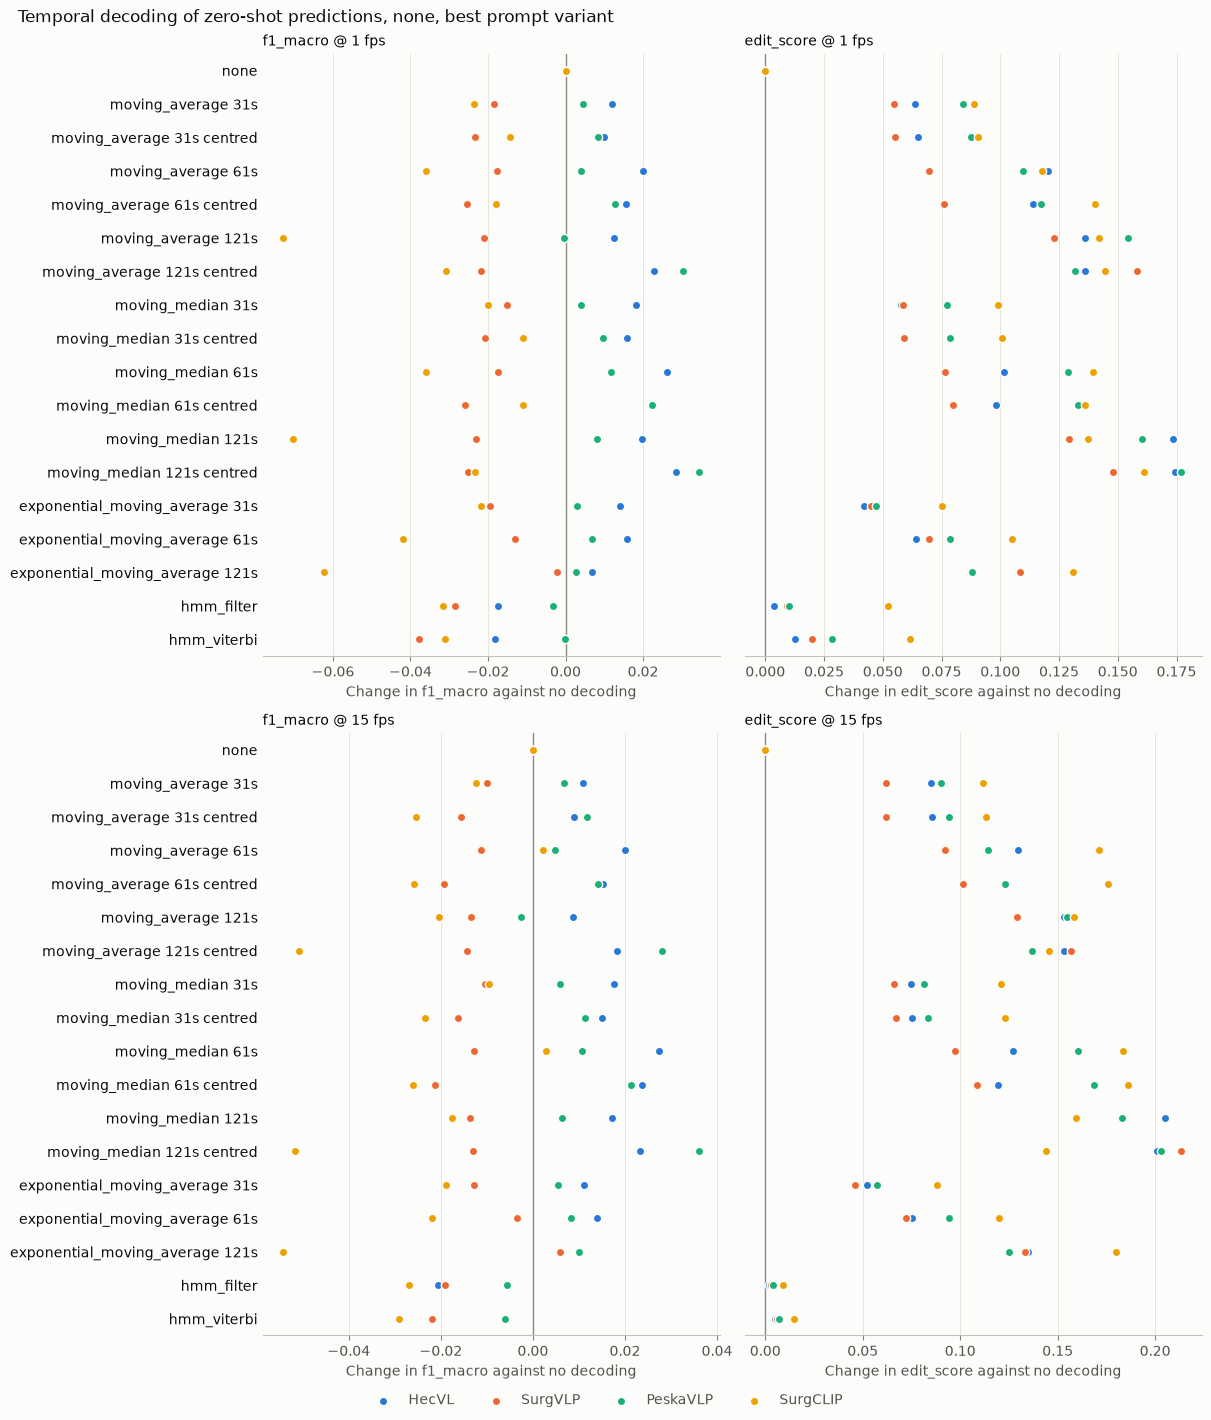

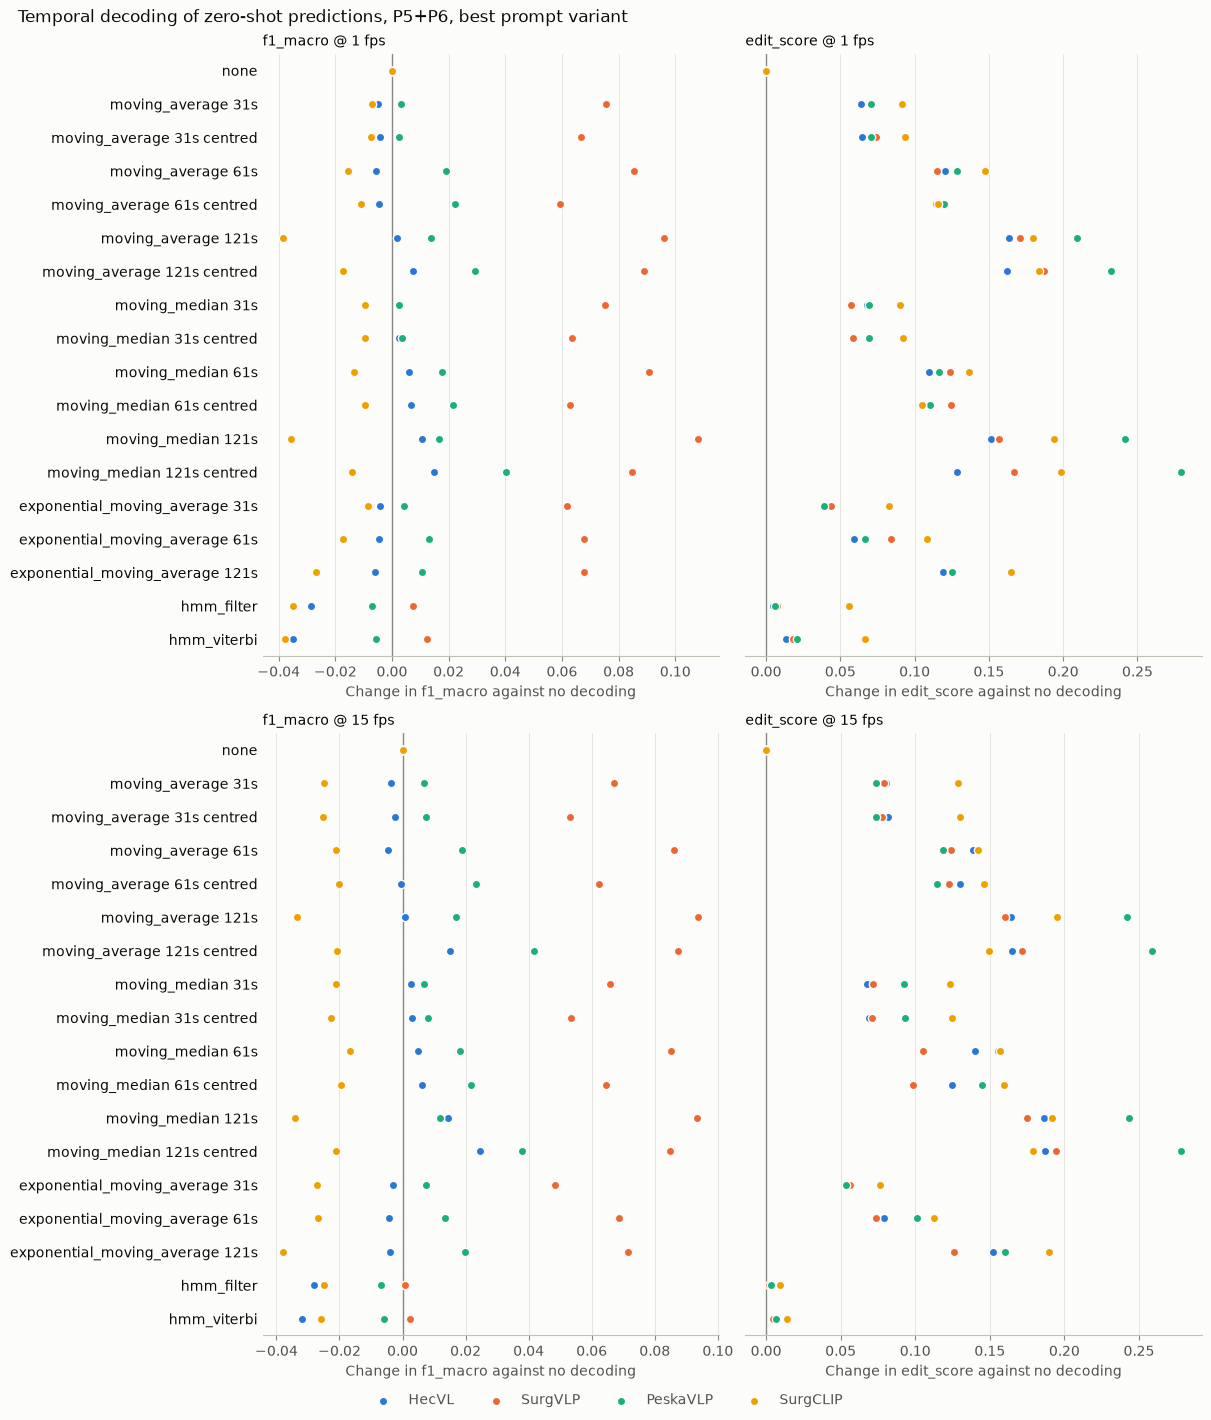

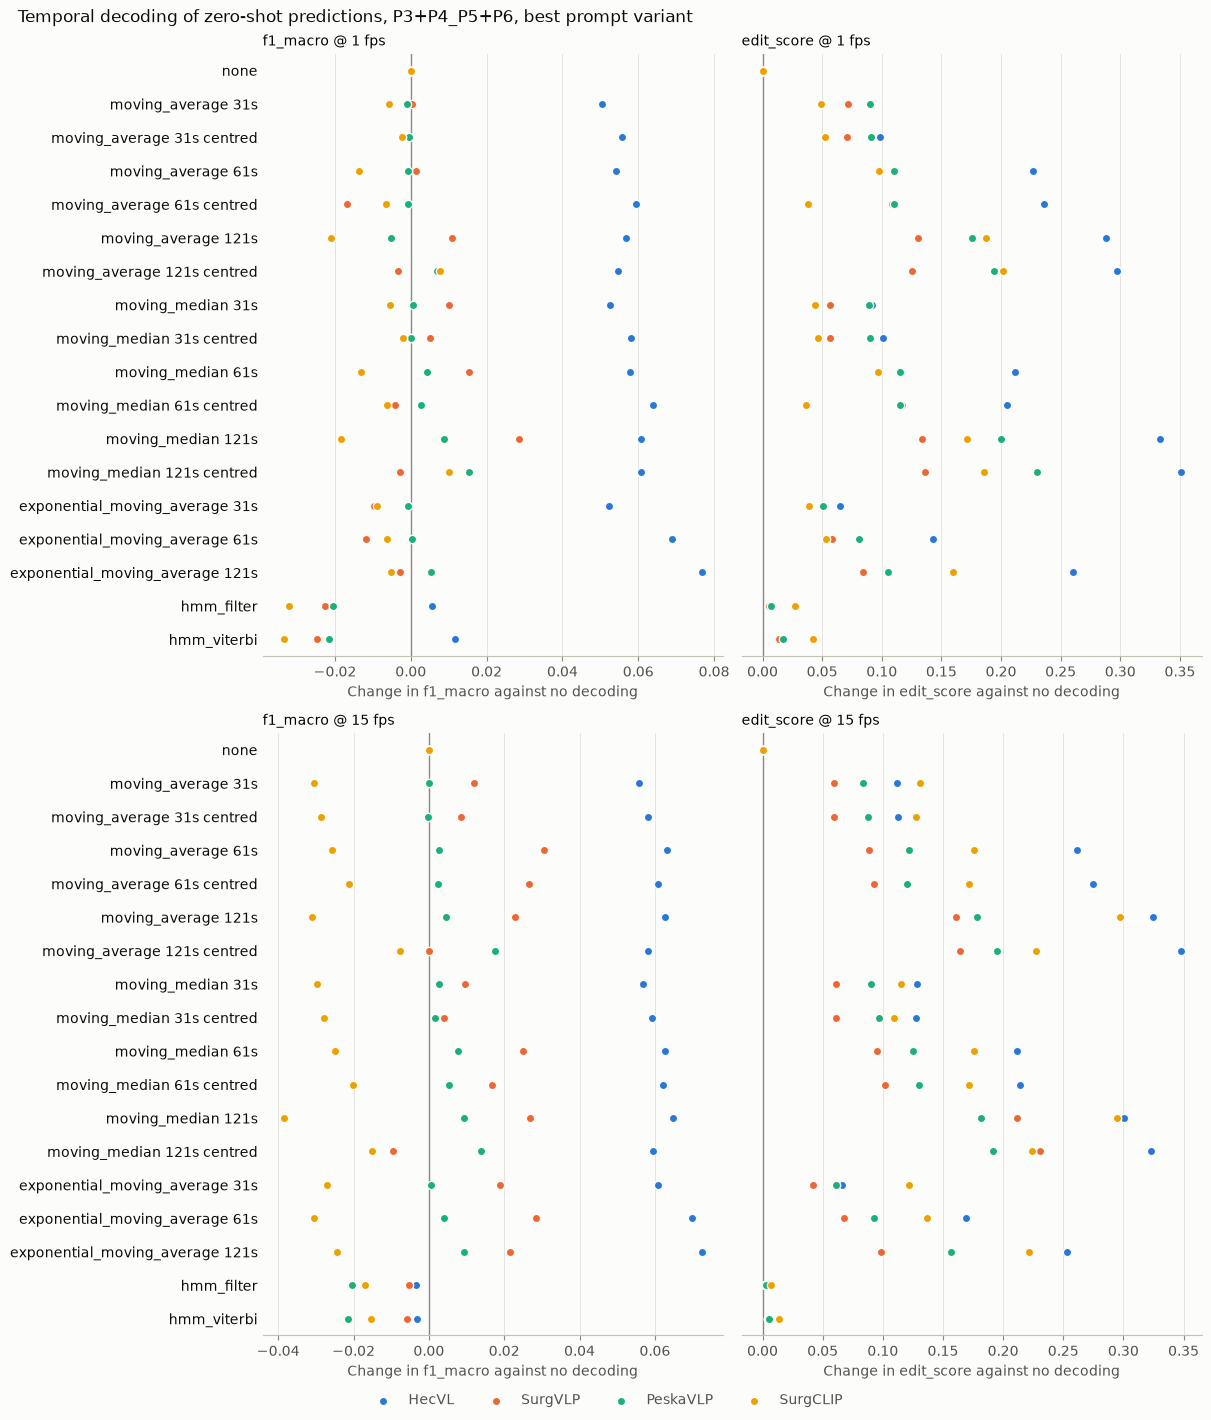

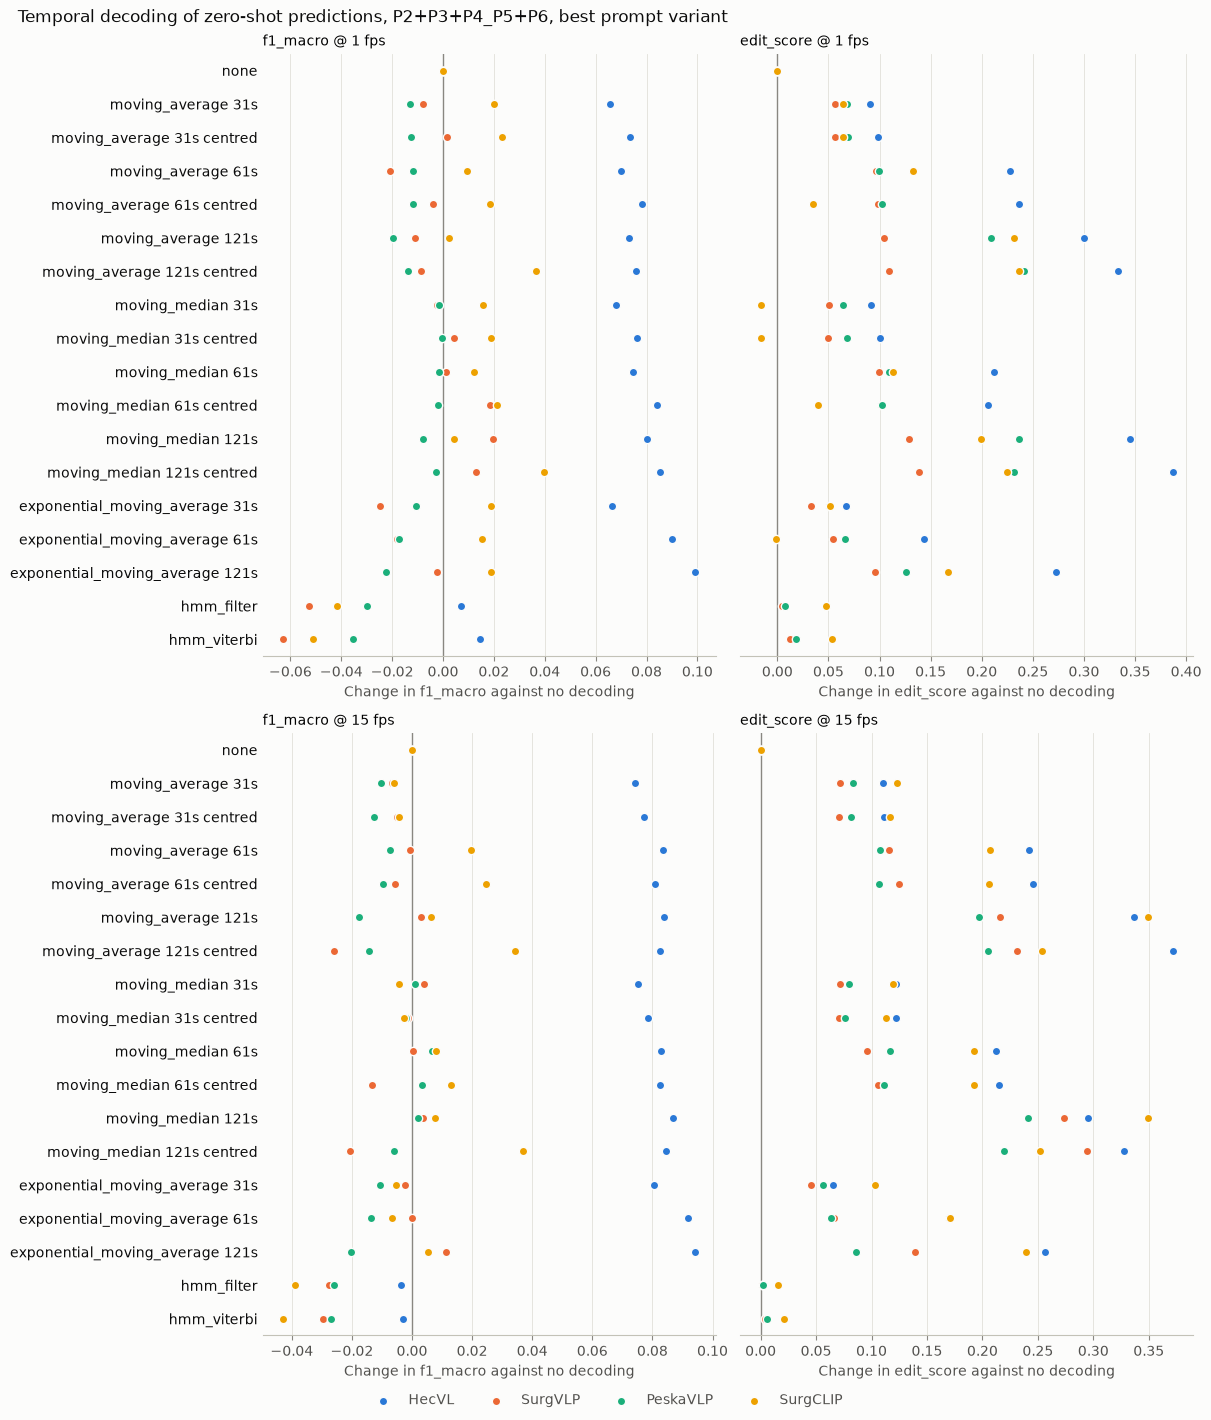

best decoding and decoded scores: highest mean over all surgeries (optimistic); f1_macro held-out: prompt variant and decoding chosen per test surgery on the other surgeries


best decoding  f1_macro none  \
scheme         model    fps                                                    
none           HecVL    1.0        moving_median 121s centred          0.110   
                        15.0                moving_median 61s          0.111   
               SurgVLP  1.0                              none          0.125   
                        15.0  exponential_moving_average 121s          0.117   
               PeskaVLP 1.0        moving_median 121s centred          0.177   
                        15.0       moving_median 121s centred          0.177   
               SurgCLIP 1.0                              none          0.176   
                        15.0                moving_median 61s          0.133   
P5+P6          HecVL    1.0        moving_median 121s centred          0.129   
                        15.0       moving_median 121s centred          0.127   
               SurgVLP  1.0                moving_median 121s          0.231   
                        15.0              moving_average 121s          0.230   
               PeskaVLP 1.0        moving_median 121s centred          0.209   
                        15.0      moving_average 121s centred          0.207   
               SurgCLIP 1.0                              none          0.199   
                        15.0                             none          0.174   
P3+P4_P5+P6    HecVL    1.0   exponential_moving_average 121s          0.127   
                        15.0  exponential_moving_average 121s          0.127   
               SurgVLP  1.0                moving_median 121s          0.229   
                        15.0               moving_average 61s          0.228   
               PeskaVLP 1.0        moving_median 121s centred          0.207   
                        15.0      moving_average 121s centred          0.206   
               SurgCLIP 1.0        moving_median 121s centred          0.244   
                        15.0                             none          0.209   
P2+P3+P4_P5+P6 HecVL    1.0   exponential_moving_average 121s          0.159   
                        15.0  exponential_moving_average 121s          0.158   
               SurgVLP  1.0                moving_median 121s          0.237   
                        15.0  exponential_moving_average 121s          0.238   
               PeskaVLP 1.0                              none          0.221   
                        15.0                moving_median 61s          0.216   
               SurgCLIP 1.0        moving_median 121s centred          0.311   
                        15.0       moving_median 121s centred          0.269   

                              f1_macro decoded  edit_score none  \
scheme         model    fps                                       
none           HecVL    1.0              0.139            0.011   
                        15.0             0.138            0.002   
               SurgVLP  1.0              0.125            0.009   
                        15.0             0.123            0.001   
               PeskaVLP 1.0              0.212            0.009   
                        15.0             0.213            0.002   
               SurgCLIP 1.0              0.176            0.053   
                        15.0             0.136            0.006   
P5+P6          HecVL    1.0              0.143            0.010   
                        15.0             0.152            0.002   
               SurgVLP  1.0              0.339            0.008   
                        15.0             0.324            0.001   
               PeskaVLP 1.0              0.250            0.010   
                        15.0             0.249            0.002   
               SurgCLIP 1.0              0.199            0.057   
                        15.0             0.174            0.007   
P3+P4_P5+P6    HecVL    1.0              0.204            0.006   
                        15.0             0.200        

In [27]:
decoding_metrics = ["f1_macro", "edit_score"]
decoding_tables = {}
for name, scheme in schemes.items():
    scores = scheme.best_results.pivot_table(index="decoding", columns=["model", "fps"], values=decoding_metrics, aggfunc="mean")
    scores = scores.reindex(index=scheme.decoding_order)
    gain = scores - scores.loc["none"]
    scheme.best_decoding = scores["f1_macro"].idxmax()

    fig, axes = plt.subplots(
        len(scheme.fps_values), len(decoding_metrics), figsize=(12, (0.32 * len(scheme.decoding_order) + 1) * len(scheme.fps_values) + 0.6),
        layout="constrained", sharey=True, squeeze=False,
    )
    for row, fps in enumerate(scheme.fps_values):
        for ax, metric in zip(axes[row], decoding_metrics, strict=True):
            clean_axes(ax, grid_axis="x")
            positions = np.arange(len(scheme.decoding_order))
            for model in models:
                if (metric, model, fps) not in gain.columns:
                    continue
                ax.scatter(
                    gain[(metric, model, fps)], positions, s=36, color=MODEL_COLORS[model], edgecolor=SURFACE,
                    linewidth=1, zorder=3, label=model,
                )
            ax.axvline(0, color=MUTED_INK, linewidth=1)
            ax.set_yticks(positions, labels=scheme.decoding_order)
            ax.set_ylim(len(scheme.decoding_order) - 0.5, -0.5)
            ax.spines["left"].set_visible(False)
            ax.tick_params(axis="y", length=0, labelcolor=INK)
            ax.set_xlabel(f"Change in {metric} against no decoding")
            ax.set_title(f"{metric} @ {fps:g} fps", loc="left", fontsize=10)
    figure_legend(fig, axes)
    fig.suptitle(f"Temporal decoding of zero-shot predictions, {name}, best prompt variant", x=0.01, ha="left", color=INK)
    plt.show()

    decoding_tables[name] = pd.DataFrame(
        {
            "best decoding": scheme.best_decoding,
            "f1_macro none": scores["f1_macro"].loc["none"],
            "f1_macro decoded": scores["f1_macro"].max(),
            "edit_score none": scores["edit_score"].loc["none"],
            "edit_score decoded": [scores[("edit_score", *key)][label] for key, label in scheme.best_decoding.items()],
            "f1_macro held-out": held_out_selection(scheme.results, ["variant", "decoding"]).groupby(["model", "fps"])["f1_macro"].mean(),
        }
    ).reindex(models, level="model")
print(
    "best decoding and decoded scores: highest mean over all surgeries (optimistic); "
    "f1_macro held-out: prompt variant and decoding chosen per test surgery on the other surgeries"
)
with_scheme(decoding_tables).round(3)

## Predicted timelines

Zero-shot phase sequence against the ground truth per surgery, raw and decoded.

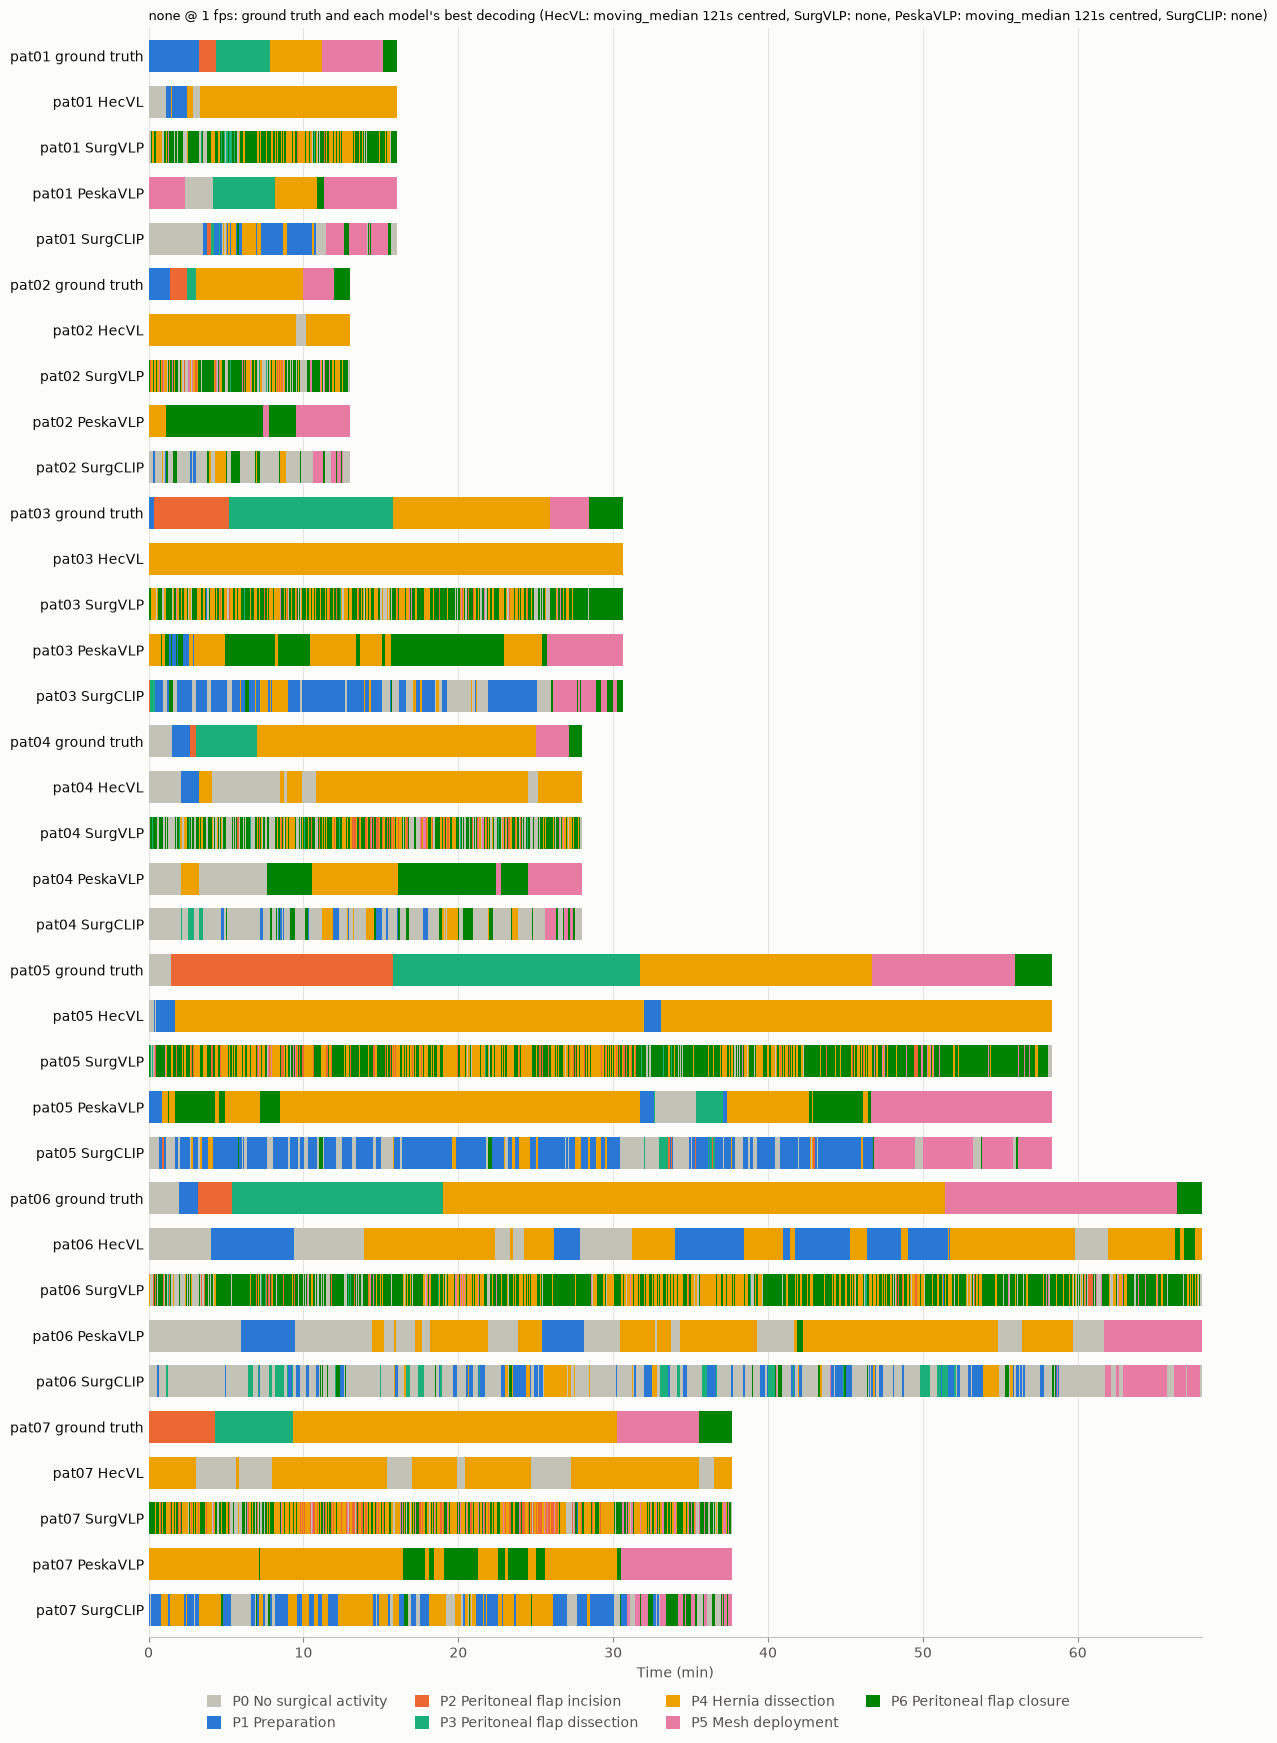

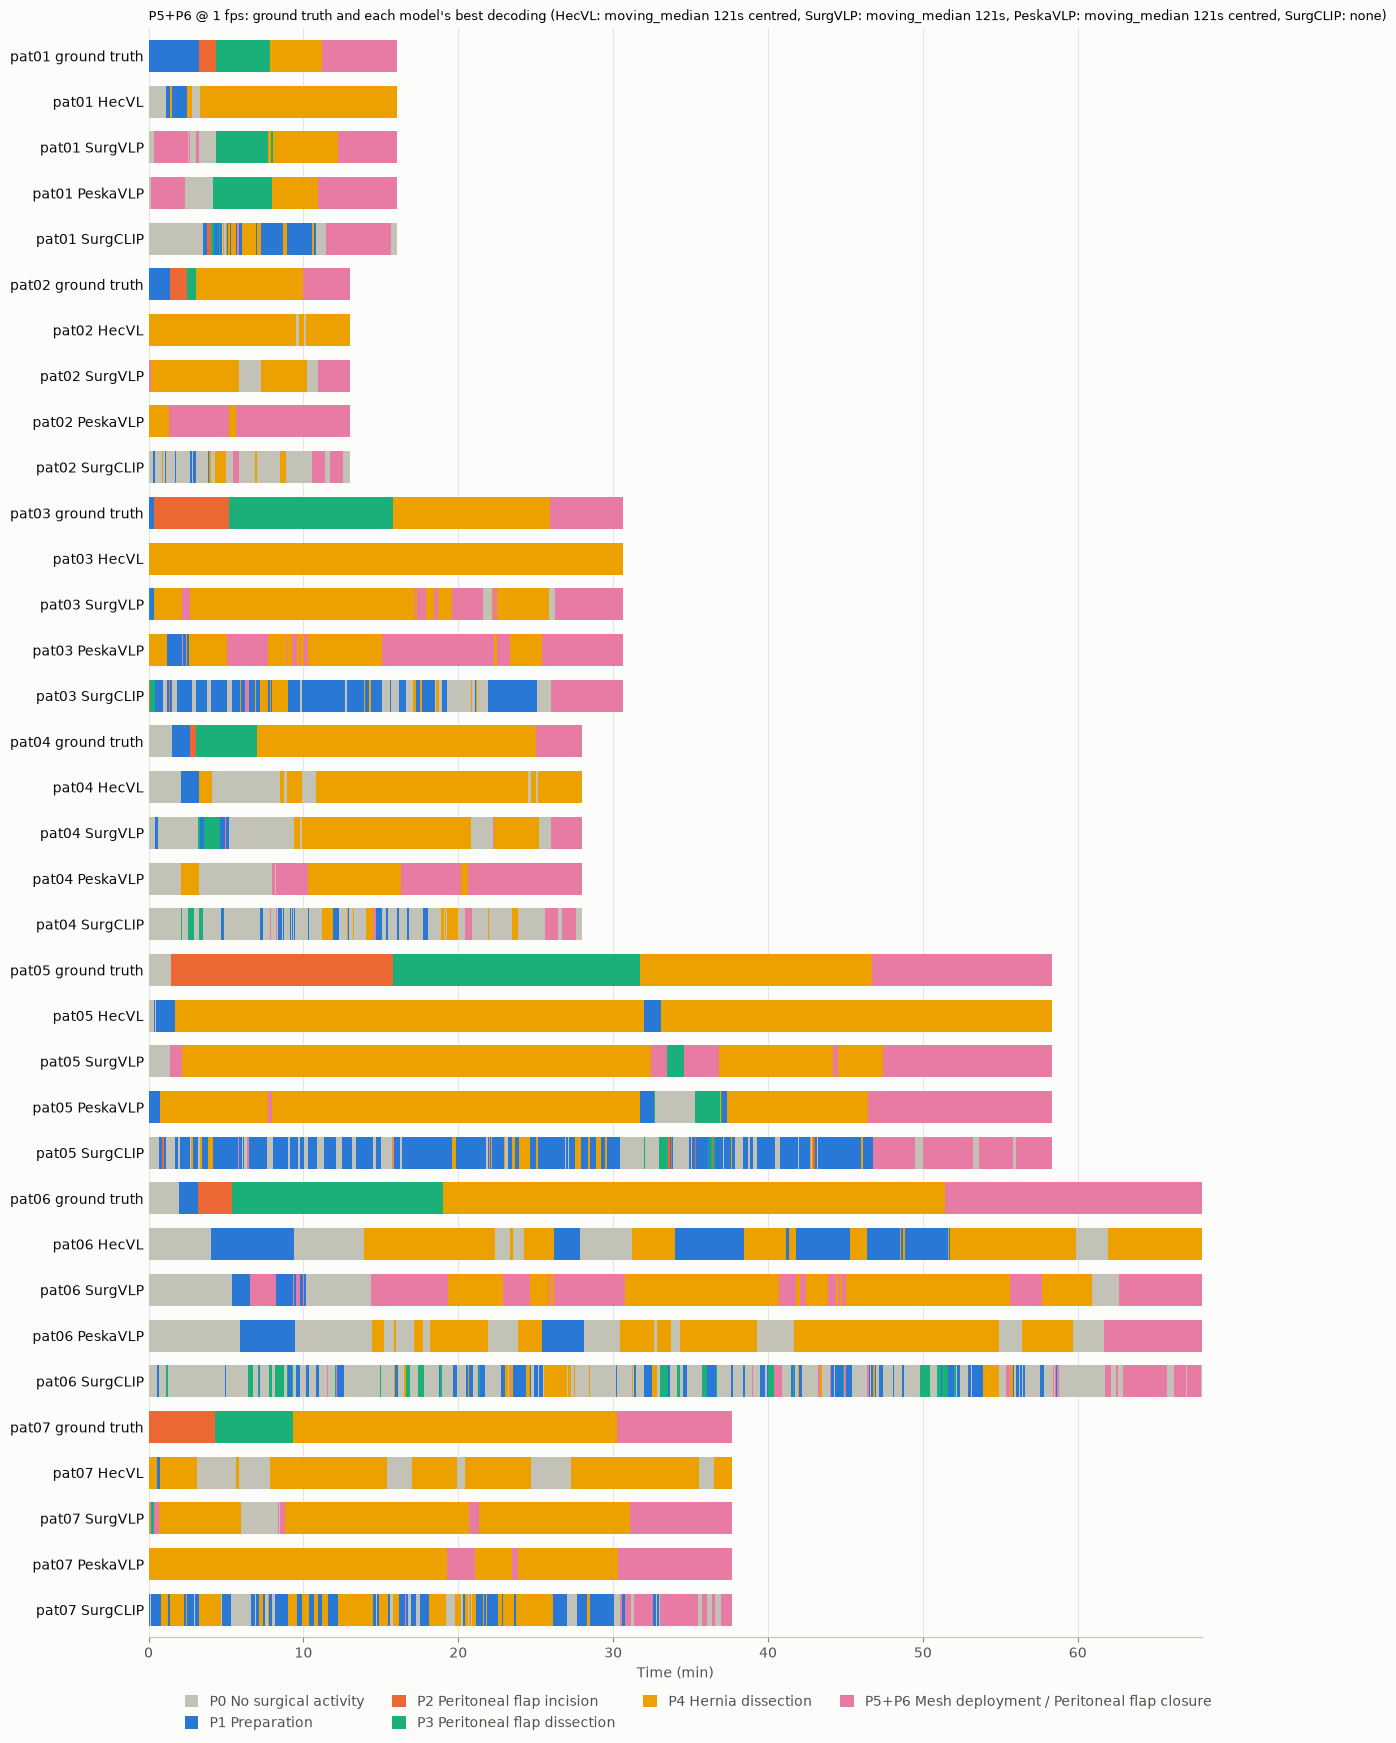

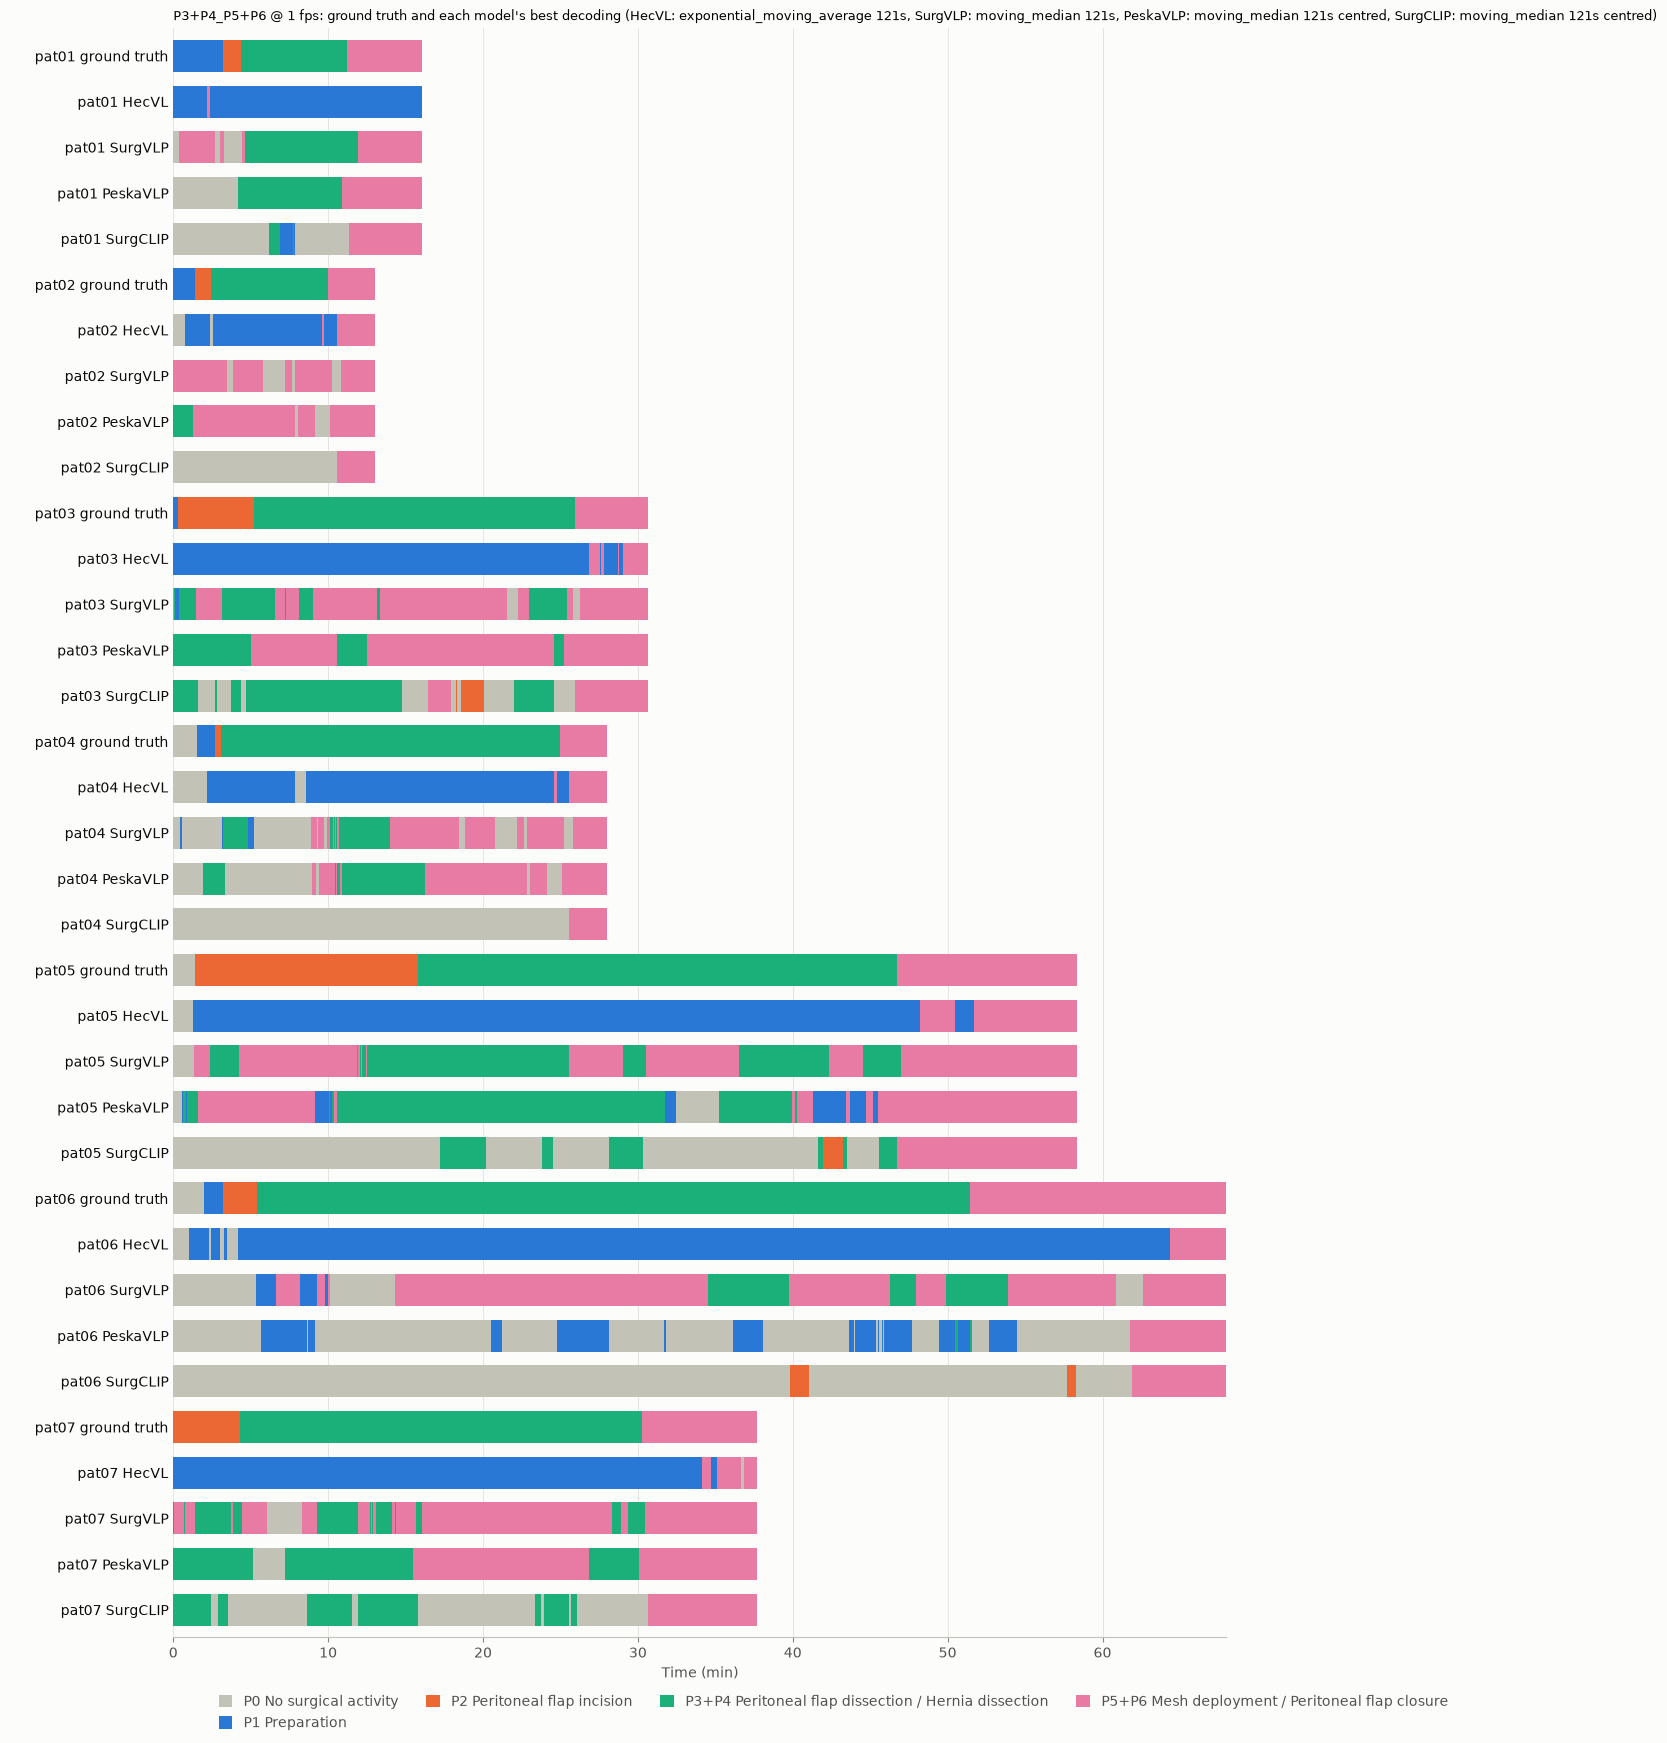

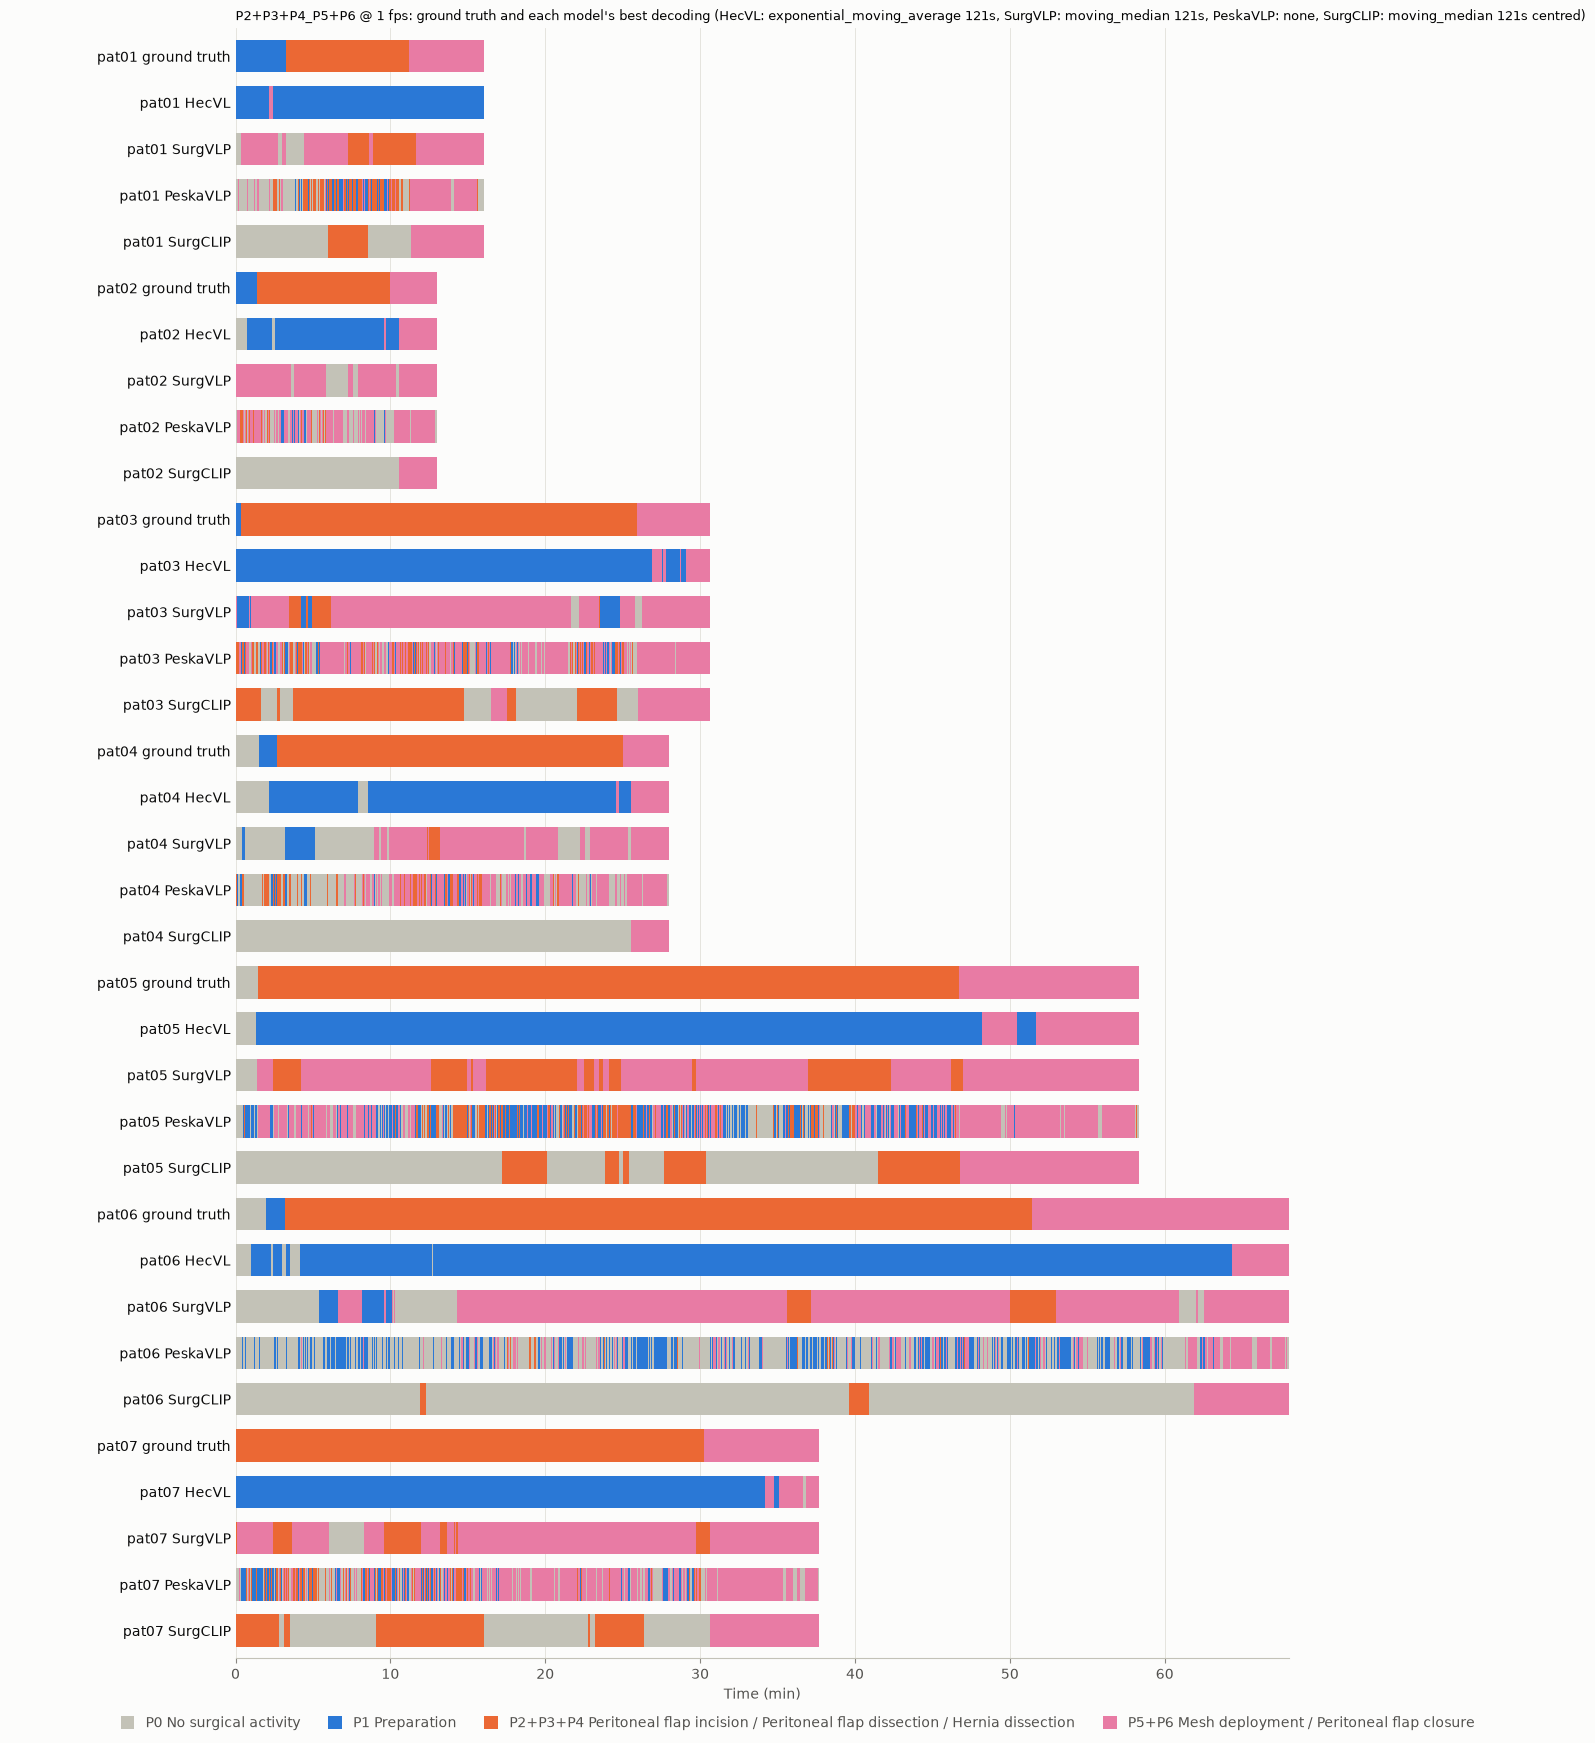

In [28]:
for name, scheme in schemes.items():
    timeline_fps = TIMELINE_FPS if TIMELINE_FPS in scheme.fps_values else scheme.fps_values[0]
    hmms = leave_one_out_hmms(
        {surgery_id: surgery.labels for surgery_id, surgery in scheme.surgeries[timeline_fps].items()},
        scheme.num_phases,
        scheme.run["hmm_pseudocount"],
    )
    rows = {}
    for surgery_id, surgery in scheme.surgeries[timeline_fps].items():
        rows[f"{surgery_id} ground truth"] = surgery.labels
        for model in models:
            key = (model, timeline_fps, scheme.best_variant.get((model, timeline_fps)))
            if key not in scheme.probabilities or surgery_id not in scheme.probabilities[key]:
                continue
            decoding = scheme.decodings_by_label[scheme.best_decoding[(model, timeline_fps)]]
            hmm = hmms[surgery_id] if decoding.method in HMM_METHODS else None
            rows[f"{surgery_id} {model}"] = decoding.apply(scheme.probabilities[key][surgery_id], timeline_fps, hmm)
    ax = plot_timeline(rows, scheme.phase_names, scheme.colors, timeline_fps)
    ax.set_title(
        f"{name} @ {timeline_fps:g} fps: ground truth and each model's best decoding "
        f"({', '.join(f'{m}: {scheme.best_decoding[(m, timeline_fps)]}' for m in models if (m, timeline_fps) in scheme.best_decoding)})",
        loc="left", fontsize=9,
    )
    plt.show()

## Per-surgery variability

Spread of macro F1 across surgeries per model. Whether some surgeries are consistently harder.

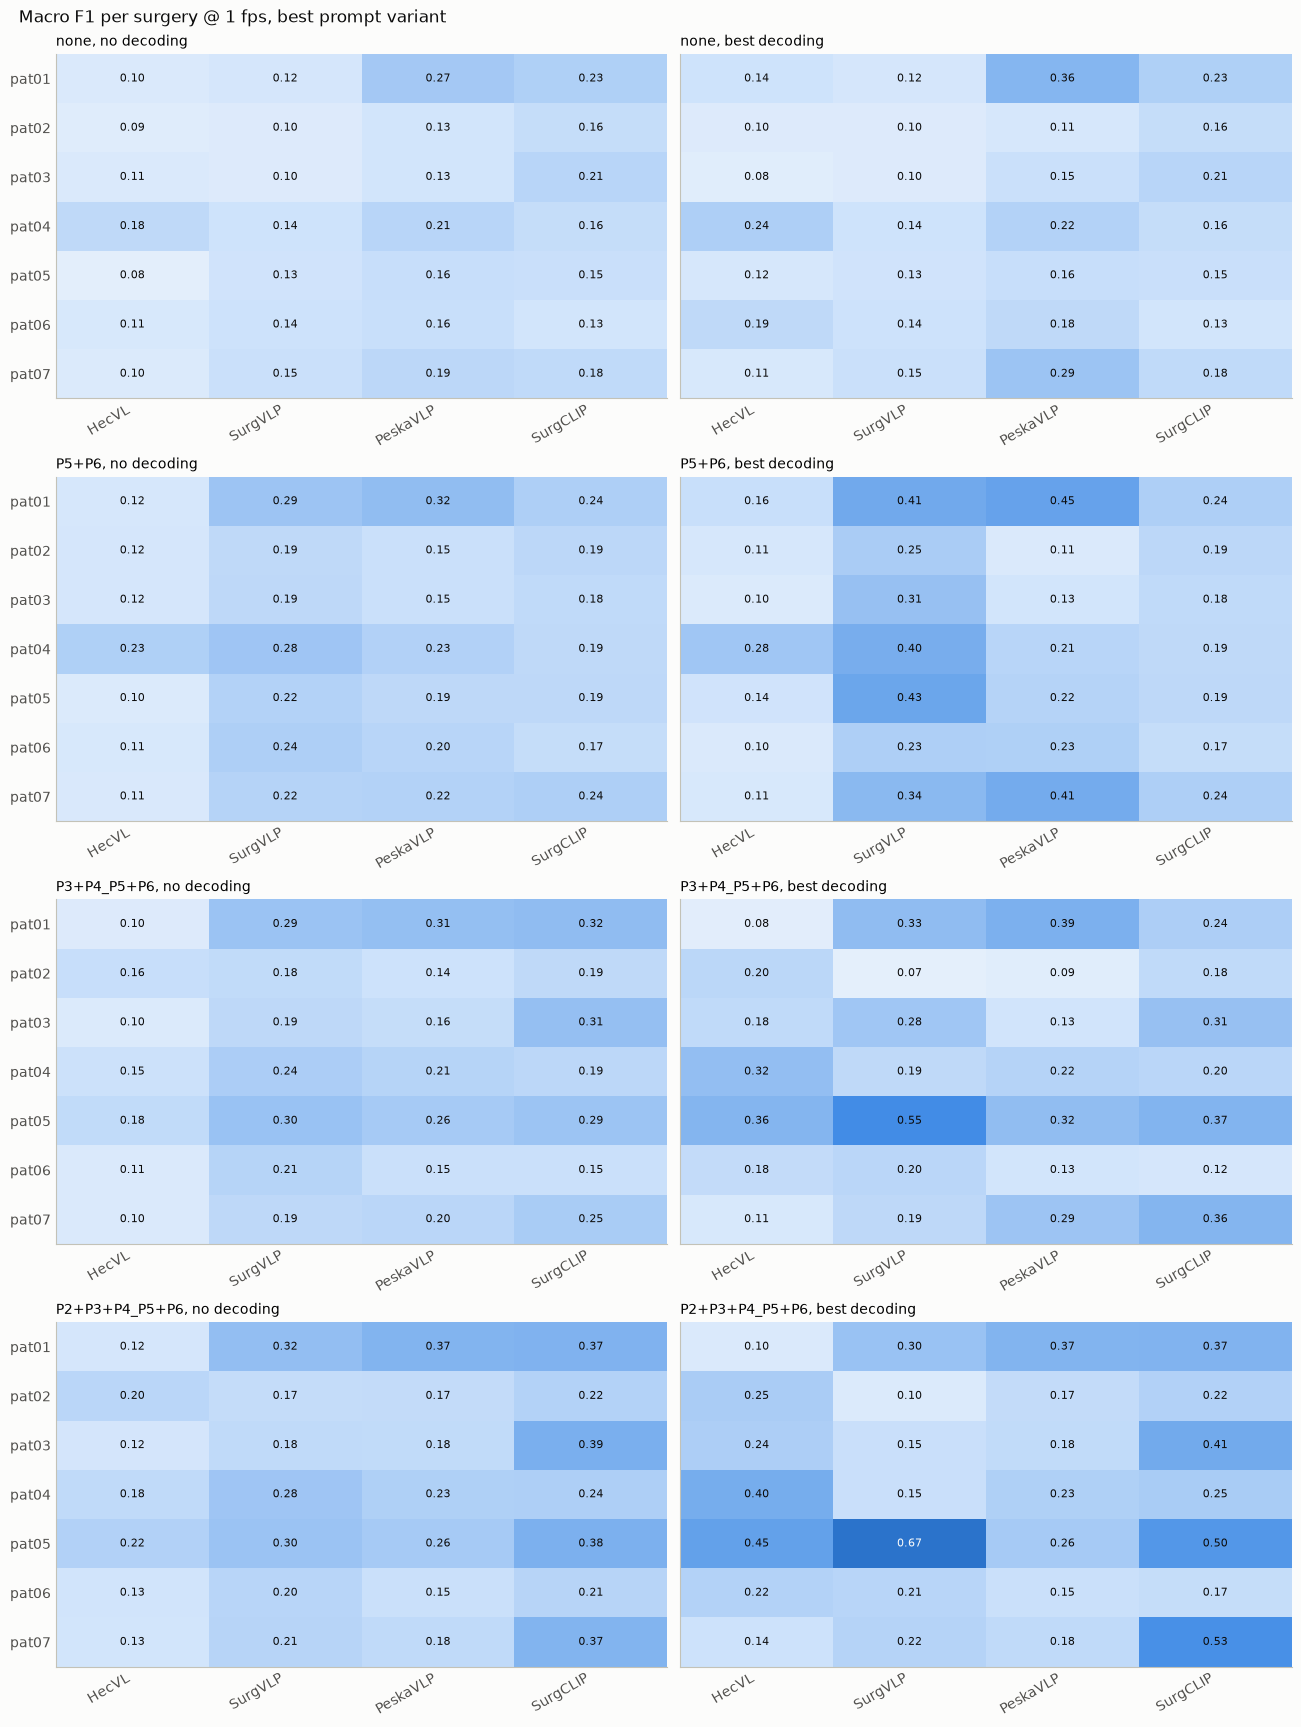

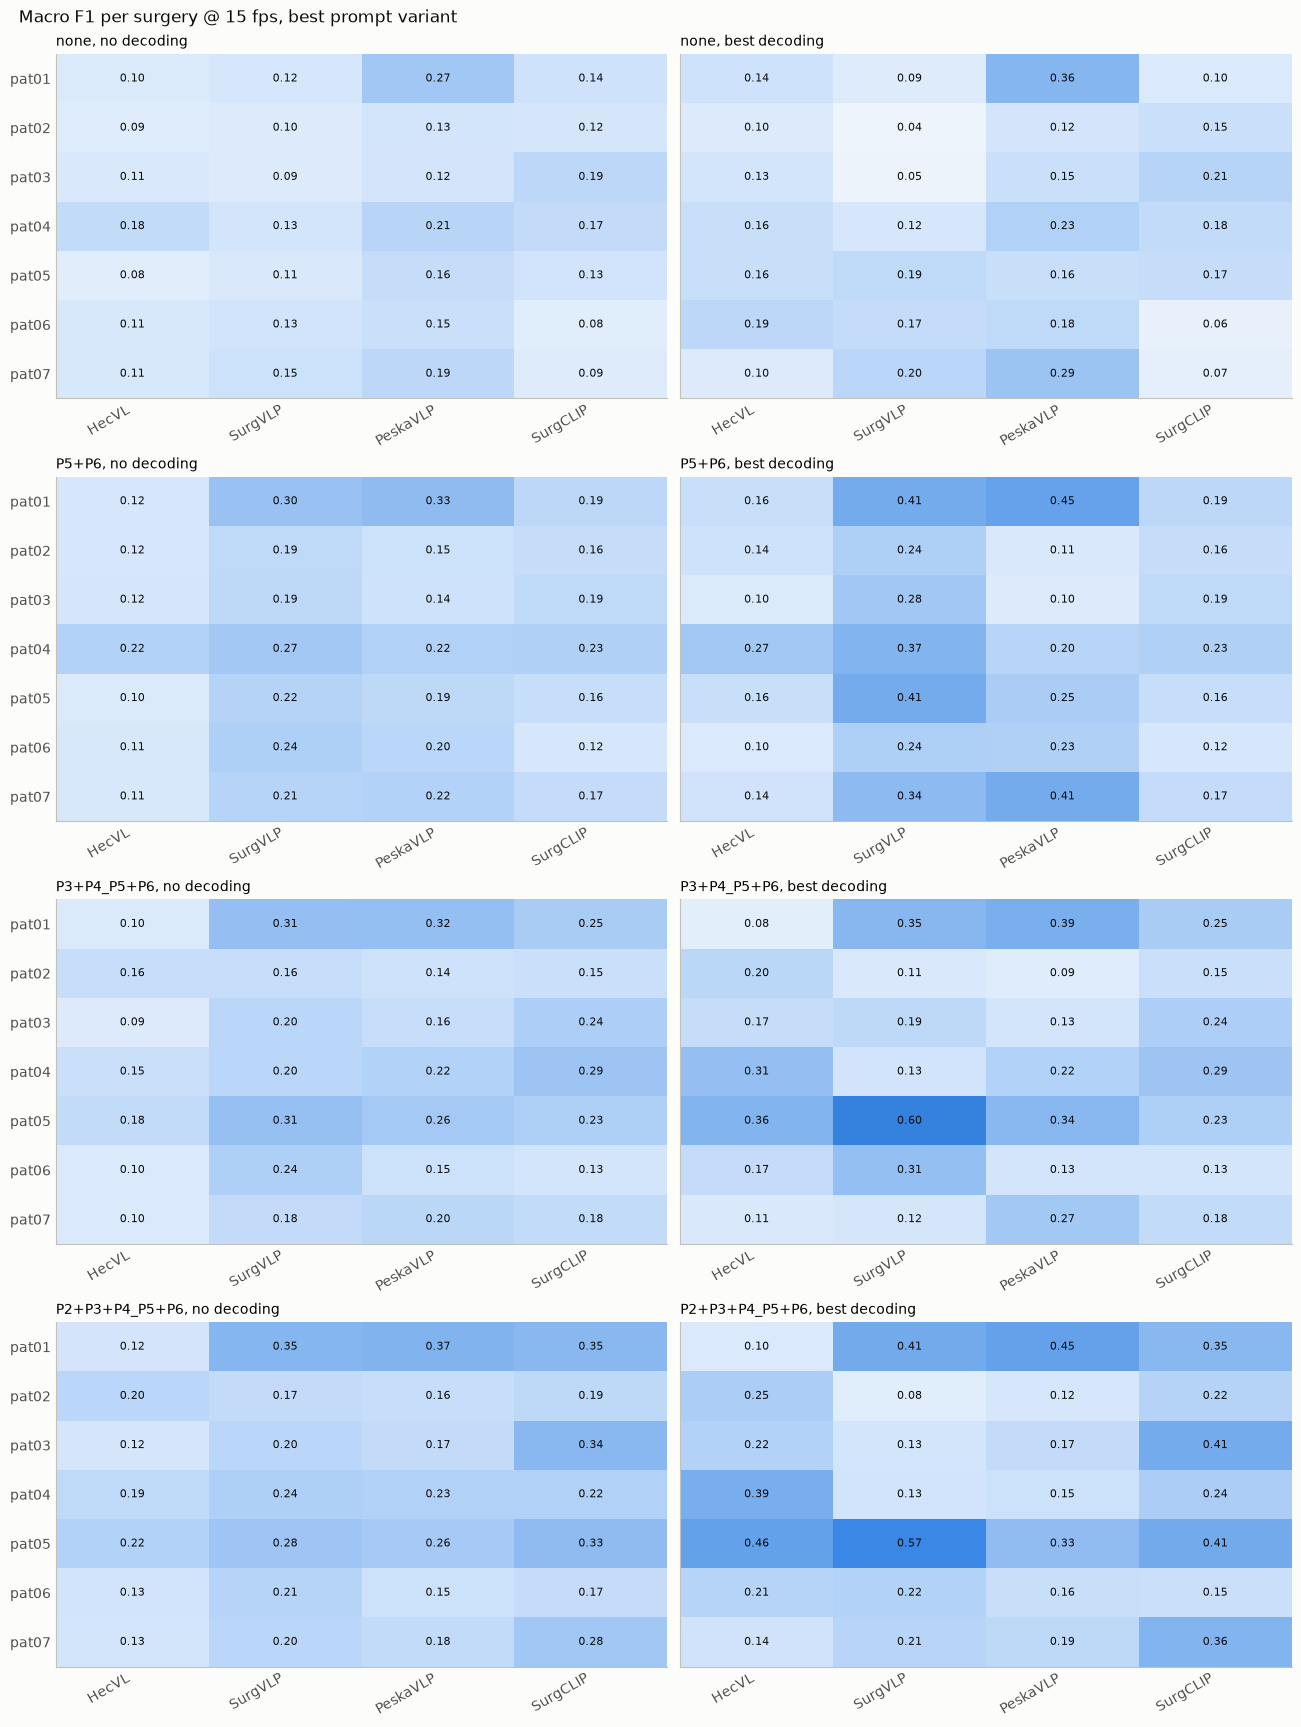

per-surgery summary over models @ 1 fps


minutes  f1_macro mean  f1_macro std  f1_macro min  \
scheme                                                                     
none           pat01   16.033          0.180         0.081         0.104   
               pat04   28.017          0.173         0.028         0.139   
               pat07   37.700          0.157         0.042         0.100   
               pat03   30.650          0.134         0.050         0.097   
               pat06   68.000          0.133         0.021         0.110   
               pat05   58.367          0.131         0.039         0.077   
               pat02   13.017          0.120         0.034         0.090   
P5+P6          pat01   16.033          0.241         0.091         0.115   
               pat04   28.017          0.232         0.039         0.187   
               pat07   37.700          0.196         0.059         0.109   
               pat06   68.000          0.179         0.054         0.109   
               pat05   58.367          0.175         0.051         0.101   
               pat02   13.017          0.162         0.035         0.117   
               pat03   30.650          0.161         0.033         0.118   
P3+P4_P5+P6    pat01   16.033          0.257         0.108         0.096   
               pat05   58.367          0.257         0.054         0.179   
               pat04   28.017          0.199         0.041         0.146   
               pat03   30.650          0.191         0.089         0.098   
               pat07   37.700          0.186         0.061         0.103   
               pat02   13.017          0.167         0.018         0.143   
               pat06   68.000          0.156         0.045         0.105   
P2+P3+P4_P5+P6 pat01   16.033          0.294         0.118         0.121   
               pat05   58.367          0.291         0.069         0.224   
               pat04   28.017          0.233         0.041         0.182   
               pat07   37.700          0.222         0.103         0.129   
               pat03   30.650          0.218         0.117         0.123   
               pat02   13.017          0.191         0.024         0.168   
               pat06   68.000          0.174         0.039         0.131   

                      f1_macro max  f1_macro decoded mean  rank  
scheme                                                           
none           pat01         0.267                  0.212     1  
               pat04         0.205                  0.190     2  
               pat07         0.194                  0.184     3  
               pat03         0.207                  0.134     4  
               pat06         0.157                  0.160     5  
               pat05         0.163                  0.141     6  
               pat02         0.164                  0.118     7  
P5+P6          pat01         0.323                  0.315     1  
               pat04         0.283                  0.267     2  
               pat07         0.237                  0.275     3  
               pat06         0.235                  0.184     4  
               pat05         0.220                  0.244     5  
               pat02         0.194                  0.166     6  
               pat03         0.191                  0.180     7  
P3+P4_P5+P6    pat01         0.324                  0.258     1  
               pat05         0.298                  0.399     2  
               pat04         0.245                  0.232     3  
               pat03         0.311                  0.224     4  
               pat07         0.250                  0.238     5  
               pat02         0.185                  0.134     6  
               pat06         0.214                  0.156     7  
P2+P3+P4_P5+P6 pat01         0.373                  0.284     1  
               pat05         0.385                  0.470     2  
               pat04         0.282                  0.260     3  
               pat07     

In [29]:
surgery_ids = sorted({s for scheme in schemes.values() for s in scheme.results["surgery_id"].unique()})
surgery_tables = {}
for fps in fps_values:
    fig, axes = plt.subplots(
        len(schemes), 2, figsize=(1.3 * len(models) * 2 + 2.5, (0.42 * len(surgery_ids) + 1.2) * len(schemes) + 0.6),
        layout="constrained", sharey=True, squeeze=False,
    )
    for row, (name, scheme) in enumerate(schemes.items()):
        decoded = scheme.best_results[
            [scheme.best_decoding.get((m, f)) == d for m, f, d in zip(
                scheme.best_results["model"], scheme.best_results["fps"], scheme.best_results["decoding"], strict=True
            )]
        ]
        views = {"no decoding": scheme.best_raw, "best decoding": decoded}
        for ax, (view, frame) in zip(axes[row], views.items(), strict=True):
            matrix = (
                frame[frame["fps"] == fps]
                .pivot_table(index="surgery_id", columns="model", values="f1_macro")
                .reindex(index=surgery_ids, columns=models)
            )
            style_axes(ax)
            ax.imshow(matrix.to_numpy(), cmap=SEQUENTIAL, vmin=0, vmax=1, aspect="auto")
            annotate_heatmap(ax, matrix.to_numpy())
            ax.set_xticks(range(len(models)), labels=models, rotation=30, ha="right")
            ax.set_yticks(range(len(surgery_ids)), labels=surgery_ids)
            ax.tick_params(length=0)
            ax.set_title(f"{name}, {view}", loc="left", fontsize=10)
        if fps == fps_values[0]:
            minutes = pd.Series({s: len(y) / fps / 60 for s, y in scheme.labels[fps].items()}, name="minutes")
            table = scheme.best_raw[scheme.best_raw["fps"] == fps].groupby("surgery_id")["f1_macro"].agg(["mean", "std", "min", "max"]).add_prefix("f1_macro ")
            table["f1_macro decoded mean"] = decoded[decoded["fps"] == fps].groupby("surgery_id")["f1_macro"].mean()
            table["rank"] = table["f1_macro mean"].rank(ascending=False).astype(int)
            surgery_tables[name] = pd.concat([minutes, table], axis=1).sort_values("rank")
    fig.suptitle(f"Macro F1 per surgery @ {fps:g} fps, best prompt variant", x=0.01, ha="left", color=INK)
    plt.show()

print(f"per-surgery summary over models @ {fps_values[0]:g} fps")
with_scheme(surgery_tables).round(3)

## Model comparison

Summary table of the metrics above, one row per model, FPS and prompt style.

In [30]:
comparison_tables = {}
for name, scheme in schemes.items():
    best_per_variant = (
        scheme.results.groupby(["model", "fps", "variant", "decoding"])["f1_macro"].mean().groupby(["model", "fps", "variant"]).agg(["idxmax", "max"])
    )
    table = (
        scheme.raw.groupby(["model", "fps", "variant"])[SUMMARY_METRICS].mean()
        .join(
            pd.DataFrame(
                {
                    "best decoding": best_per_variant["idxmax"].map(lambda index: index[3]),
                    "f1_macro decoded": best_per_variant["max"],
                    "f1_macro decoded held-out": held_out_selection(scheme.results, ["decoding"], by=("model", "fps", "variant"))
                    .groupby(["model", "fps", "variant"])["f1_macro"]
                    .mean(),
                }
            )
        )
        .join(calibration.loc[name][["mean confidence", "ECE"]])
        .join(bias.loc[name][["top share", "normalised entropy", "total variation"]])
    )
    comparison_tables[name] = table.reindex(pd.MultiIndex.from_tuples(scheme.keys, names=table.index.names))
with_scheme(comparison_tables).round(3)

accuracy  f1_macro  \
scheme         model    fps  variant                                     
none           HecVL    1.0  narrative                 0.115     0.078   
                             descriptive               0.279     0.110   
                             narrative+descriptive     0.073     0.070   
                        15.0 narrative                 0.114     0.078   
                             descriptive               0.279     0.111   
...                                                      ...       ...   
P2+P3+P4_P5+P6 SurgCLIP 1.0  descriptive               0.371     0.311   
                             narrative+descriptive     0.249     0.263   
                        15.0 narrative                 0.179     0.224   
                             descriptive               0.271     0.269   
                             narrative+descriptive     0.204     0.238   

                                                    edit_score  f1_at_25  \
scheme         model    fps  variant                                       
none           HecVL    1.0  narrative                   0.007     0.002   
                             descriptive                 0.011     0.001   
                             narrative+descriptive       0.012     0.002   
                        15.0 narrative                   0.001     0.000   
                             descriptive                 0.002     0.000   
...                                                        ...       ...   
P2+P3+P4_P5+P6 SurgCLIP 1.0  descriptive                 0.126     0.072   
                             narrative+descriptive       0.073     0.051   
                        15.0 narrative                   0.006     0.001   
                             descriptive                 0.016     0.004   
                             narrative+descriptive       0.008     0.001   

                                                                      best decoding  \
scheme         model    fps  variant                                                  
none           HecVL    1.0  narrative              exponential_moving_average 121s   
                             descriptive                 moving_median 121s centred   
                             narrative+descriptive                             none   
                        15.0 narrative              exponential_moving_average 121s   
                             descriptive                          moving_median 61s   
...                                                                             ...   
P2+P3+P4_P5+P6 SurgCLIP 1.0  descriptive                 moving_median 121s centred   
                             narrative+descriptive                             none   
                        15.0 narrative                   moving_average 61s centred   
                             descriptive                 moving_median 121s centred   
                             narrative+descriptive                             none   

                                                    f1_macro decoded  \
scheme         model    fps  variant                                   
none           HecVL    1.0  narrative                         0.120   
                             descriptive                       0.139   
                             narrative+descriptive             0.070   
                        15.0 narrative                         0.115   
                             descriptive                       0.138   
...                                                              ...   
P2+P3+P4_P5+P6 SurgCLIP 1.0  descriptive                       0.351   
                             narrative+descriptive             0.263   
                        15.0 narrative                         0.231   
                             descriptive                       0.306   
                             narrative+descriptive             0.238   

                               

## Phase merge schemes

Zero-shot runs for every scheme in `MERGE_SCHEMES`: `none` is the ground truth with the seven phases of `assets/phases/default.json`; the variants merge `P5+P6`, then additionally `P3+P4` (flap dissection with hernia dissection) or `P2+P3+P4` (all dissection). Merged phases pool the prompts of their members.

In [31]:
pd.DataFrame(
    {
        name: {
            "classes": scheme.num_phases,
            "merged": ", ".join(label for label in scheme.phase_ids if "+" in label) or "none (ground truth)",
            "phases": ", ".join(scheme.phase_ids),
            "rows": len(scheme.results),
        }
        for name, scheme in schemes.items()
    }
).T

,classes,merged,phases,rows
none,7,none (ground truth),"P0, P1, P2, P3, P4, P5, P6",3024
P5+P6,6,P5+P6,"P0, P1, P2, P3, P4, P5+P6",3024
P3+P4_P5+P6,5,"P3+P4, P5+P6","P0, P1, P2, P3+P4, P5+P6",3024
P2+P3+P4_P5+P6,4,"P2+P3+P4, P5+P6","P0, P1, P2+P3+P4, P5+P6",3024


## Merge scheme comparison

Macro F1, precision, IoU and accuracy per model and scheme, without decoding and with the decoding chosen on the other surgeries, against the majority-class baseline of each scheme.

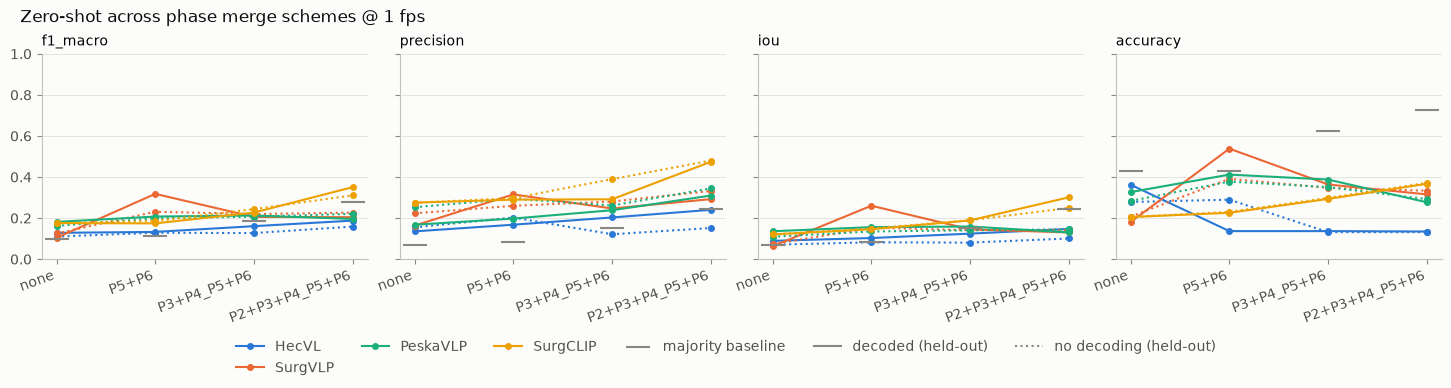

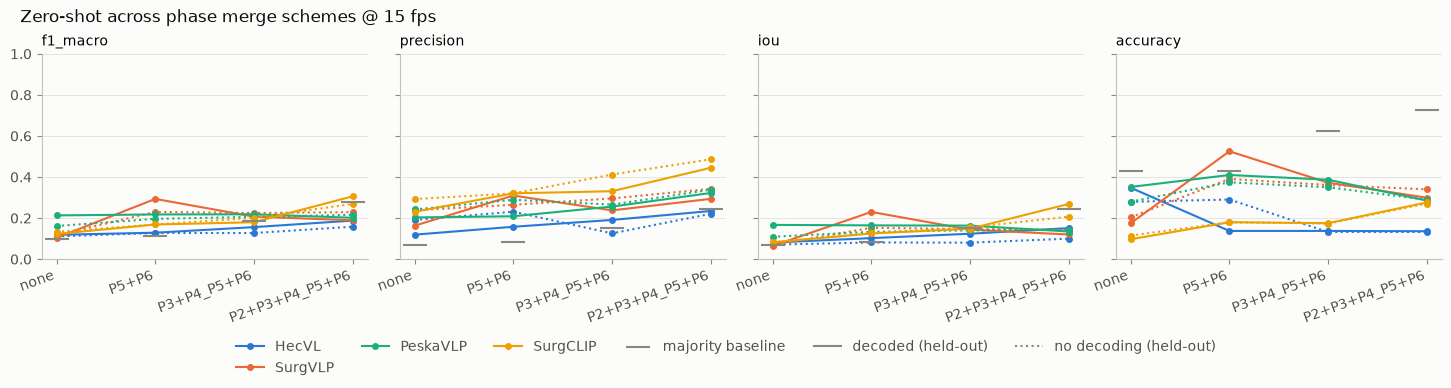

prompt variant and decoding chosen per test surgery on the other surgeries, mean over surgeries


f1_macro                                        \
scheme            none                                 P5+P6   
view           decoded majority baseline no decoding decoded   
model    fps                                                   
HecVL    1.0     0.128               NaN       0.110   0.133   
         15.0    0.119               NaN       0.111   0.129   
SurgVLP  1.0     0.104               NaN       0.125   0.318   
         15.0    0.104               NaN       0.117   0.293   
PeskaVLP 1.0     0.181               NaN       0.162   0.207   
         15.0    0.213               NaN       0.161   0.218   
SurgCLIP 1.0     0.176               NaN       0.176   0.174   
         15.0    0.123               NaN       0.133   0.169   
majority 1.0       NaN             0.096         NaN     NaN   
         15.0      NaN             0.096         NaN     NaN   

                                                                           \
scheme                                      P3+P4_P5+P6                     
view          majority baseline no decoding     decoded majority baseline   
model    fps                                                                
HecVL    1.0                NaN       0.129       0.161               NaN   
         15.0               NaN       0.127       0.156               NaN   
SurgVLP  1.0                NaN       0.231       0.206               NaN   
         15.0               NaN       0.230       0.207               NaN   
PeskaVLP 1.0                NaN       0.199       0.213               NaN   
         15.0               NaN       0.196       0.218               NaN   
SurgCLIP 1.0                NaN       0.185       0.227               NaN   
         15.0               NaN       0.169       0.180               NaN   
majority 1.0              0.115         NaN         NaN             0.188   
         15.0             0.115         NaN         NaN             0.188   

                                          ...         iou          \
scheme                    P2+P3+P4_P5+P6  ...        none   P5+P6   
view          no decoding        decoded  ... no decoding decoded   
model    fps                              ...                       
HecVL    1.0        0.127          0.188  ...       0.070   0.103   
         15.0       0.127          0.188  ...       0.071   0.102   
SurgVLP  1.0        0.220          0.204  ...       0.073   0.260   
         15.0       0.225          0.189  ...       0.069   0.230   
PeskaVLP 1.0        0.207          0.196  ...       0.109   0.156   
         15.0       0.206          0.201  ...       0.109   0.164   
SurgCLIP 1.0        0.244          0.351  ...       0.121   0.146   
         15.0       0.201          0.306  ...       0.081   0.125   
majority 1.0          NaN            NaN  ...         NaN     NaN   
         15.0         NaN            NaN  ...         NaN     NaN   

                                                                           \
scheme                                      P3+P4_P5+P6                     
view          majority baseline no decoding     decoded majority baseline   
model    fps                                                                
HecVL    1.0                NaN       0.082       0.124               NaN   
         15.0               NaN       0.081       0.124               NaN   
SurgVLP  1.0                NaN       0.153       0.145               NaN   
         15.0               NaN       0.153       0.144               NaN   
PeskaVLP 1.0                NaN       0.135       0.159               NaN   
         15.0               NaN       0.133       0.163               NaN   
SurgCLIP 1.0                NaN       0.149       0.189               NaN   
         15.0               NaN       0.125       0.148               NaN   
majority 1.0              0.085         NaN         NaN             0.153   
         15.0             0.084         NaN         NaN             0.

In [32]:
comparison_rows = []
for name, scheme in schemes.items():
    for view, selected in (
        ("no decoding", held_out_selection(scheme.raw, ["variant"])),
        ("decoded", held_out_selection(scheme.results, ["variant", "decoding"])),
    ):
        summary = selected.groupby(["model", "fps"])[COMPARE_METRICS].mean().reset_index()
        comparison_rows += summary.assign(scheme=name, view=view).to_dict("records")
majority = baselines[baselines["baseline"] == "majority"].groupby(["scheme", "fps"])[COMPARE_METRICS].mean().reset_index()
comparison_rows += majority.assign(view="majority baseline", model="majority").to_dict("records")
scheme_comparison = pd.DataFrame(comparison_rows)

positions = np.arange(len(scheme_names))
for fps in fps_values:
    plot_table = scheme_comparison[scheme_comparison["fps"] == fps]
    fig, axes = plt.subplots(1, len(COMPARE_METRICS), figsize=(3.6 * len(COMPARE_METRICS), 3.8), layout="constrained", sharey=True)
    for ax, metric in zip(axes, COMPARE_METRICS, strict=True):
        clean_axes(ax)
        for model in models:
            for view, style in (("decoded", "-"), ("no decoding", ":")):
                values = plot_table[(plot_table["model"] == model) & (plot_table["view"] == view)].set_index("scheme")[metric]
                ax.plot(
                    positions, values.reindex(scheme_names), linestyle=style, marker="o", markersize=4,
                    color=MODEL_COLORS[model], label=model if view == "decoded" else None,
                )
        baseline_values = plot_table[plot_table["view"] == "majority baseline"].set_index("scheme")[metric]
        ax.scatter(positions, baseline_values.reindex(scheme_names), marker="_", s=300, color=MUTED_INK, zorder=3, label="majority baseline")
        ax.set_xticks(positions, labels=scheme_names, rotation=20, ha="right")
        ax.set_ylim(0, 1)
        ax.set_title(metric, loc="left", fontsize=10)
    axes[0].plot([], [], color=MUTED_INK, linestyle="-", label="decoded (held-out)")
    axes[0].plot([], [], color=MUTED_INK, linestyle=":", label="no decoding (held-out)")
    figure_legend(fig, axes)
    fig.suptitle(f"Zero-shot across phase merge schemes @ {fps:g} fps", x=0.01, ha="left", color=INK)
    plt.show()

print("prompt variant and decoding chosen per test surgery on the other surgeries, mean over surgeries")
(
    scheme_comparison.pivot_table(index=["model", "fps"], columns=["scheme", "view"], values=["f1_macro", "iou"])
    .reindex(columns=scheme_names, level="scheme")
    .reindex([*models, "majority"], level="model")
    .round(3)
)

## Per-phase performance across merge schemes

F1 per phase and model for each scheme. Shows which merges remove the confusions.

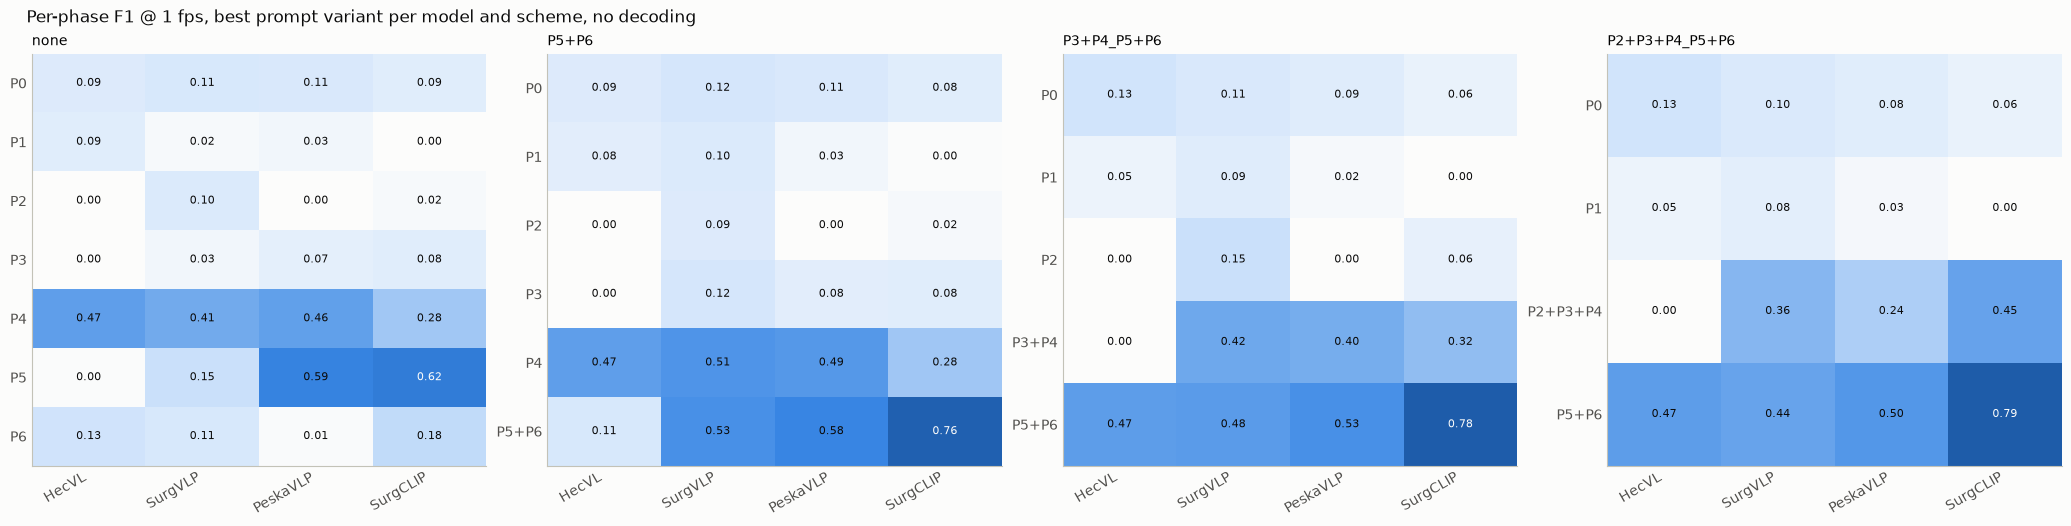

none
  P0 No surgical activity
  P1 Preparation
  P2 Peritoneal flap incision
  P3 Peritoneal flap dissection
  P4 Hernia dissection
  P5 Mesh deployment
  P6 Peritoneal flap closure
P5+P6
  P0 No surgical activity
  P1 Preparation
  P2 Peritoneal flap incision
  P3 Peritoneal flap dissection
  P4 Hernia dissection
  P5+P6 Mesh deployment / Peritoneal flap closure
P3+P4_P5+P6
  P0 No surgical activity
  P1 Preparation
  P2 Peritoneal flap incision
  P3+P4 Peritoneal flap dissection / Hernia dissection
  P5+P6 Mesh deployment / Peritoneal flap closure
P2+P3+P4_P5+P6
  P0 No surgical activity
  P1 Preparation
  P2+P3+P4 Peritoneal flap incision / Peritoneal flap dissection / Hernia dissection
  P5+P6 Mesh deployment / Peritoneal flap closure


In [33]:
comparison_fps = TIMELINE_FPS if TIMELINE_FPS in fps_values else fps_values[0]
fig, axes = plt.subplots(
    1, len(schemes), figsize=(1.1 * len(models) * len(schemes) + 3, 0.45 * max(s.num_phases for s in schemes.values()) + 2),
    layout="constrained", squeeze=False,
)
for ax, (name, scheme) in zip(axes[0], schemes.items(), strict=True):
    matrix = (
        per_phase[(per_phase["scheme"] == name) & (per_phase["fps"] == comparison_fps)]
        .pivot(index="phase", columns="model", values="f1")
        .reindex(index=scheme.phase_ids, columns=models)
    )
    style_axes(ax)
    ax.imshow(matrix.to_numpy(), cmap=SEQUENTIAL, vmin=0, vmax=1, aspect="auto")
    annotate_heatmap(ax, matrix.to_numpy())
    ax.set_xticks(range(len(models)), labels=models, rotation=30, ha="right")
    ax.set_yticks(range(scheme.num_phases), labels=scheme.phase_ids)
    ax.tick_params(length=0)
    ax.set_title(name, loc="left", fontsize=10)
fig.suptitle(
    f"Per-phase F1 @ {comparison_fps:g} fps, best prompt variant per model and scheme, no decoding", x=0.01, ha="left", color=INK
)
plt.show()

for name, scheme in schemes.items():
    print(name)
    for phase_name in scheme.phase_names:
        print(f"  {phase_name}")

## Confusion matrices across merge schemes

Row-normalised confusion matrices per model and scheme.

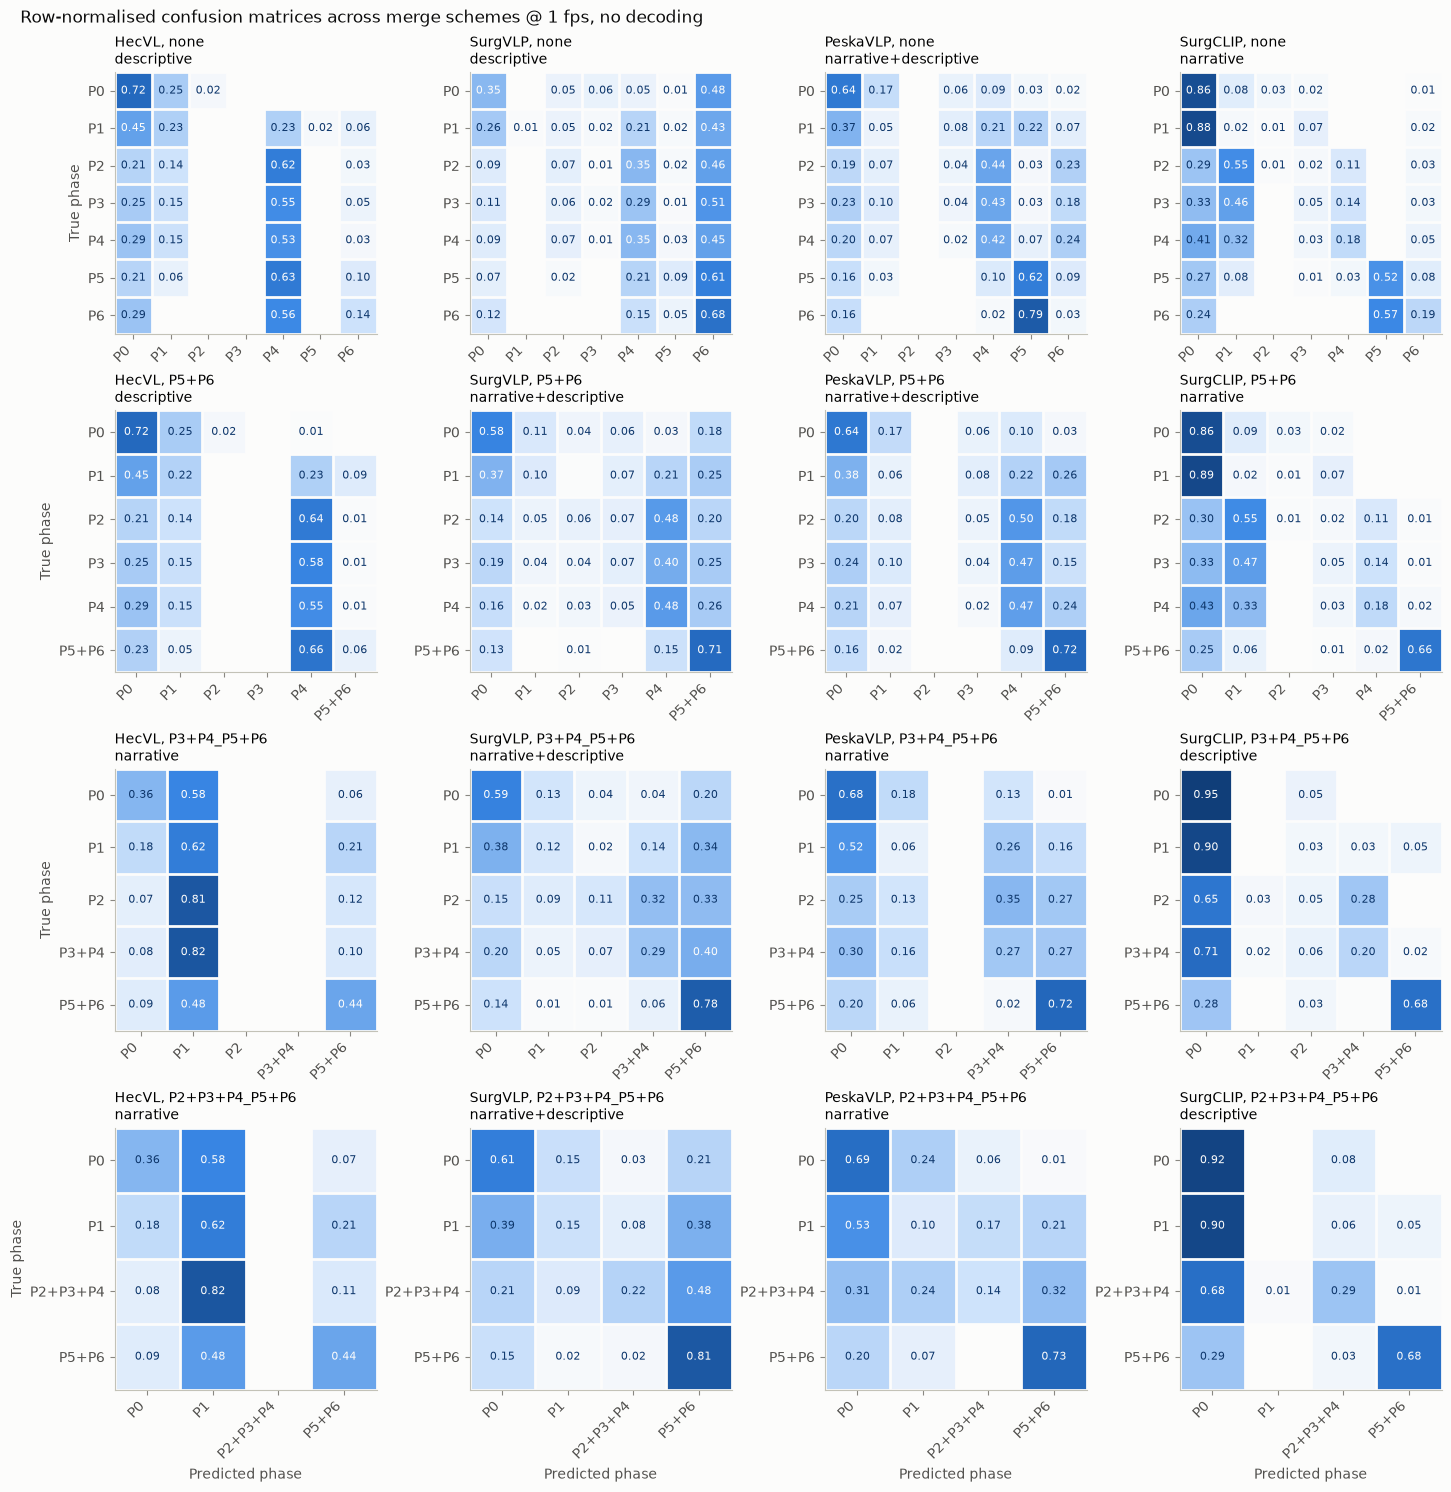

In [34]:
fig, axes = plt.subplots(
    len(schemes), len(models), figsize=(3.6 * len(models), 3.6 * len(schemes) + 0.4), layout="constrained", squeeze=False
)
for row, (name, scheme) in enumerate(schemes.items()):
    for column, model in enumerate(models):
        ax = axes[row][column]
        key = (model, comparison_fps, scheme.best_variant.get((model, comparison_fps)))
        if key not in scheme.probabilities:
            ax.set_visible(False)
            continue
        y, p = pooled(scheme, key)
        plot_confusion_matrix(y, p.argmax(axis=1), scheme.phase_ids, ax=ax)
        ax.set_title(f"{model}, {name}\n{key[2]}", loc="left", fontsize=10)
        if column:
            ax.set_ylabel("")
        if row < len(schemes) - 1:
            ax.set_xlabel("")
fig.suptitle(f"Row-normalised confusion matrices across merge schemes @ {comparison_fps:g} fps, no decoding", x=0.01, ha="left", color=INK)
plt.show()